# Evolutionary stability of ethics in pharma: analysis notebook

This notebook makes every figure in the paper. The model itself (fit, fixed points,
thresholds, conserved quantity, Lyapunov exponents) is in `egt_core.py`; a copy of it is
embedded below so the notebook also runs on its own, e.g. in Colab.

To run: open in Jupyter (or `uv run jupyter lab`) and Run All.
Seeds are fixed, so the figures come out the same every time. Figures are
saved to `figures/`.

The composite indices in `data/pharma_indices.csv` were built from the raw FDA, DOJ,
SEC and public-pressure series before any modeling (paper Sec. 2.4):
* x = 0.4(1 - recalls) + 0.3(1 - warning letters) + 0.3(audit pass rate)
* y = 0.5(inspection activity) + 0.5(enforcement activity)
* z = average of litigation, media coverage and trust indicators
* k = average of approval delay, compliance cost and administrative burden

(each raw series is min-max scaled to [0, 1] over 2010-2024 first)

In [1]:
import sys, types, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patheffects as pe
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.signal import convolve2d, find_peaks
from scipy.stats import skew, kurtosis, gaussian_kde
from sklearn.metrics import r2_score, mean_squared_error

EGT_CORE_SOURCE = r'''"""
Model code for the pharma compliance paper.

The system is

    xdot = x(1-x) (a0 + ay*y + az*z)    ethical firms
    ydot = y(1-y) (b0 + bx*x)           active regulators
    zdot = z(1-z) (c0 + cx*x)           active public

with a0 = -C_base, ay = S_pol + alpha - k^3, az = gamma,
b0 = B_r - C_r, bx = -B_r, c0 = B_p - C_p, cx = -B_p.

The notebook and the paper both pull their numbers from here.
"""
from __future__ import annotations

from functools import lru_cache
from pathlib import Path
import io

import numpy as np
import pandas as pd
from scipy.integrate import odeint
from scipy.optimize import minimize

try:
    _HERE = Path(__file__).resolve().parent
except NameError:  # running inside a notebook
    _HERE = Path.cwd()

# Copies of the two data files, used if data/ isn't next to this file
# (e.g. when the notebook is uploaded to Colab by itself).
_EMBEDDED_INDICES = """Year,Evolutionary_t,Ethical_Firms_x,Regulators_y,Public_z,Friction_k
2010,0,0.65,0.20,0.15,0.60
2012,2,0.72,0.30,0.18,0.65
2014,4,0.78,0.45,0.25,0.70
2016,6,0.85,0.60,0.35,0.75
2018,8,0.80,0.75,0.50,0.80
2020,10,0.60,0.85,0.65,0.88
2022,12,0.40,0.92,0.80,0.95
2024,14,0.25,0.88,0.90,1.05
"""
_EMBEDDED_FIRMS = r"""firm,strategy_zone,rnd_pct_of_revenue,rnd_basis,rnd_source,total_penalties_musd,penalty_basis,penalty_source,revenue_2019_musd,revenue_basis,source_access_date
Teva,S2,6.0,"R&D 1,010 / revenues 16,887 (FY2019 Form 10-K)",https://www.sec.gov/Archives/edgar/data/818686/000119312520044221/d852939d10k.htm,2326,Public Citizen (2024) Table 4: federal+state total 1991-2021,https://www.citizen.org/wp-content/uploads/2681.pdf,16887.0,revenues FY2019 (Form 10-K),2026-10-14
Abbott,S2,7.6,"R&D 2,440 / net sales 31,904 (FY2019 Form 10-K)",https://www.sec.gov/Archives/edgar/data/1800/000110465920023904/abt-20191231x10k59d41b.htm,2009,Public Citizen (2024) Table 4: federal+state total 1991-2021,https://www.citizen.org/wp-content/uploads/2681.pdf,31904.0,net sales FY2019 (Form 10-K),2026-10-14
Mylan,S2,5.6,"R&D 639.9 / total revenues 11,500.5 (FY2019 Form 10-K)",https://www.sec.gov/Archives/edgar/data/0001623613/000162361320000011/myl10k20191231doc.htm,1210,Public Citizen (2024) Table 4: federal+state total 1991-2021,https://www.citizen.org/wp-content/uploads/2681.pdf,11500.5,total revenues FY2019 (Form 10-K),2026-10-14
Indivior,S2,6.8,R&D 53 / net revenue 785 (FY2019 results),https://www.investegate.co.uk/announcement/rns/indivior--indv/final-results/6248224,1183,Public Citizen (2024) Table 4: federal+state total 1991-2021,https://www.citizen.org/wp-content/uploads/2681.pdf,785.0,net revenue FY2019 (FY2019 results announcement),2026-10-14
Mallinckrodt,Mixed,11.0,"R&D 349.4 / net sales 3,162.5 = 11.0% (FY2019 Form 10-K)",https://www.sec.gov/Archives/edgar/data/0001567892/000156789220000005/mnk10-k122719.htm,1754,Public Citizen (2024) Table 4: federal+state total 1991-2021,https://www.citizen.org/wp-content/uploads/2681.pdf,3162.5,net sales FY2019 (Form 10-K),2026-10-14
J&J,Mixed,13.8,"R&D 11,355 / sales 82,059 (FY2019 Form 10-K; R&D as summarized by Nasdaq, Aug 2020)",https://www.nasdaq.com/articles/top-5-spenders-in-rd-in-biotech-2020-08-12,8449,Public Citizen (2024) Table 4: federal+state total 1991-2021,https://www.citizen.org/wp-content/uploads/2681.pdf,82059.0,sales FY2019 (Form 10-K),2026-10-14
GSK,Mixed,13.5,"R&D GBP 4,568M / turnover GBP 33,754M (FY2019 results announcement)",https://www.gsk.com/media/5820/fy-2019-results-announcement.pdf,7921,Public Citizen (2024) Table 4: federal+state total 1991-2021,https://www.citizen.org/wp-content/uploads/2681.pdf,43920.0,turnover FY2019 in USD,2026-10-14
Pfizer,Mixed,16.7,"R&D 8,650 / revenues 51,750 (FY2019 Form 10-K, as reported; Nasdaq summary Aug 2020)",https://www.nasdaq.com/articles/top-5-spenders-in-rd-in-biotech-2020-08-12,4773,Public Citizen (2024) Table 4: federal+state total 1991-2021,https://www.citizen.org/wp-content/uploads/2681.pdf,51750.0,revenues FY2019 as reported in the FY2019 Form 10-K,2026-10-14
Amgen,Mixed,17.6,"R&D 4,116 / total revenues 23,362 (FY2019 Form 10-K)",https://www.sec.gov/Archives/edgar/data/0000318154/000031815420000017/amgn-12312019x10kq42019.htm,939,Public Citizen (2024) Table 4: federal+state total 1991-2021,https://www.citizen.org/wp-content/uploads/2681.pdf,23362.0,total revenues FY2019 (Form 10-K),2026-10-14
Allergan,Mixed,11.3,"R&D 1,812.0 / total net revenues 16,088.9 (FY2019 Form 10-K)",https://www.sec.gov/Archives/edgar/data/1578845/000156459020005038/agn-10k_20191231.htm,816,Public Citizen (2024) Table 4: federal+state total 1991-2021,https://www.citizen.org/wp-content/uploads/2681.pdf,16088.9,total net revenues FY2019 (Form 10-K),2026-10-14
Novartis,Mixed,19.8,"R&D 9,402 / net sales 47,445 = 19.8% (FY2019 annual report; Nasdaq summary Aug 2020)",https://www.nasdaq.com/articles/top-5-spenders-in-rd-in-biotech-2020-08-12,2948,Public Citizen (2024) Table 4: federal+state total 1991-2021,https://www.citizen.org/wp-content/uploads/2681.pdf,47445.0,"net sales FY2019, continuing operations",2026-10-14
Merck,S1,21.1,"R&D 9,872 / sales 46,840 = 21.07% (FY2019 Form 10-K; Nasdaq summary Aug 2020)",https://www.nasdaq.com/articles/top-5-spenders-in-rd-in-biotech-2020-08-12,1840,Public Citizen (2024) Table 4: federal+state total 1991-2021,https://www.citizen.org/wp-content/uploads/2681.pdf,46840.0,sales FY2019 (Form 10-K),2026-10-14
Eli Lilly,S1,25.1,"R&D 5,595.0 / revenue 22,319.5 = 25.1% (2019 Financial Report)",https://investor.lilly.com/static-files/34d71960-241f-4160-bd20-86fb85df4def,1742,Public Citizen (2024) Table 4: federal+state total 1991-2021,https://www.citizen.org/wp-content/uploads/2681.pdf,22319.5,revenue FY2019,2026-10-14
AstraZeneca,S1,24.8,"R&D 6,059 / total revenue 24,384 (FY2019 Form 20-F)",https://www.sec.gov/Archives/edgar/data/901832/000110465920028557/a20-5700_1ex15d1.htm,1035,Public Citizen (2024) Table 4: federal+state total 1991-2021,https://www.citizen.org/wp-content/uploads/2681.pdf,24384.0,total revenue FY2019 (Form 20-F),2026-10-14
BMS,S1,23.5,"R&D 6,148 / total revenues 26,145 (FY2019 results, Form 8-K exhibit 99.2)",https://www.sec.gov/Archives/edgar/data/14272/000001427220000075/q42019ex992.htm,1823,Public Citizen (2024) Table 4: federal+state total 1991-2021,https://www.citizen.org/wp-content/uploads/2681.pdf,26145.0,total revenues FY2019,2026-10-14
"""


def _read(name, fallback):
    for c in (_HERE / "data" / name, _HERE / name):
        if c.exists():
            return pd.read_csv(c)
    return pd.read_csv(io.StringIO(fallback))


def load_indices():
    return _read("pharma_indices.csv", _EMBEDDED_INDICES)


def load_firms():
    return _read("firm_classification.csv", _EMBEDDED_FIRMS)


# calibration
# Order of the fitted constants everywhere below.
PARAM_NAMES = ["C_base", "S_pol", "alpha", "B_r", "C_r", "gamma", "B_p", "C_p"]
# Bounds: costs and penalties in (0, 1]; benefits at least the matching costs.
BOUNDS = [(0.1, 0.5), (0.1, 1.0), (0.1, 1.0), (0.5, 1.0),
          (0.1, 0.5), (0.1, 1.0), (0.4, 1.0), (0.1, 0.5)]
INITIAL_GUESS = [0.2, 0.4, 0.2, 0.8, 0.25, 0.6, 0.6, 0.15]
X_WEIGHT = 8.0          # extra weight on the compliance series
TIME_WEIGHTS = (1.0, 3.0)  # later years weighted more


def _sys_training(state, t, params, t_emp, k_emp):
    x, y, z = (min(1 - 1e-5, max(1e-5, v)) for v in state)
    C_b, S_p, alp, B_r, C_r, gam, B_p, C_p = params
    k_t = np.interp(t, t_emp, k_emp)  # friction follows the data between observations
    F = -(C_b + k_t**3 * y) + y * (S_p + alp) + z * gam
    return [x * (1 - x) * F,
            y * (1 - y) * ((1 - x) * B_r - C_r),
            z * (1 - z) * ((1 - x) * B_p - C_p)]


def _wmse(a, b, w=None):
    w = np.ones_like(a) if w is None else w
    return float(np.sum(w * (a - b) ** 2) / np.sum(w))


def _columns(df):
    return (df[c].values for c in
            ["Evolutionary_t", "Ethical_Firms_x", "Regulators_y", "Public_z", "Friction_k"])


def calibrate(df=None):
    """L-BFGS-B fit of the eight constants to the biennial indices."""
    df = load_indices() if df is None else df
    t, x, y, z, k = _columns(df)
    w = np.linspace(*TIME_WEIGHTS, len(t))

    def loss(p):
        try:
            sol = odeint(_sys_training, [x[0], y[0], z[0]], t, args=(p, t, k))
            return X_WEIGHT * _wmse(x, sol[:, 0], w) + _wmse(y, sol[:, 1]) + _wmse(z, sol[:, 2])
        except Exception:
            return 1e6

    res = minimize(loss, INITIAL_GUESS, method="L-BFGS-B", bounds=BOUNDS)
    return dict(zip(PARAM_NAMES, res.x)), res


@lru_cache(maxsize=1)
def fitted_params():
    p, _ = calibrate()
    return tuple(p[n] for n in PARAM_NAMES)


def P(**changes):
    """Fitted constants as a dict; pass e.g. S_pol=0.5 to change one."""
    d = dict(zip(PARAM_NAMES, fitted_params()))
    d.update(changes)
    return d


def calibrated_path(t_eval, df=None):
    df = load_indices() if df is None else df
    t, x, y, z, k = _columns(df)
    return odeint(_sys_training, [x[0], y[0], z[0]], t_eval, args=(fitted_params(), t, k))


# constant-k model
K_BASELINE = 0.60  # friction index in 2010


def k_mean_historical(df=None):
    df = load_indices() if df is None else df
    return float(df["Friction_k"].mean())  # 0.7975 (between k* and k**)


def coefficients(p, k):
    return dict(a0=-p["C_base"], ay=p["S_pol"] + p["alpha"] - k**3, az=p["gamma"],
                b0=p["B_r"] - p["C_r"], bx=-p["B_r"],
                c0=p["B_p"] - p["C_p"], cx=-p["B_p"])


def rhs(state, t, p, k):
    x, y, z = state
    c = coefficients(p, k)
    return [x * (1 - x) * (c["a0"] + c["ay"] * y + c["az"] * z),
            y * (1 - y) * (c["b0"] + c["bx"] * x),
            z * (1 - z) * (c["c0"] + c["cx"] * x)]


def jacobian(state, p, k):
    x, y, z = state
    c = coefficients(p, k)
    F = c["a0"] + c["ay"] * y + c["az"] * z
    G = c["b0"] + c["bx"] * x
    H = c["c0"] + c["cx"] * x
    return np.array([[(1 - 2 * x) * F, x * (1 - x) * c["ay"], x * (1 - x) * c["az"]],
                     [y * (1 - y) * c["bx"], (1 - 2 * y) * G, 0.0],
                     [z * (1 - z) * c["cx"], 0.0, (1 - 2 * z) * H]])


def _expit(u):
    return 0.5 * (1.0 + np.tanh(0.5 * u))  # logistic without overflow


def simulate(x0, t, k=K_BASELINE, p=None, **changes):
    """Integrate at constant k.

    We integrate u = ln(x/(1-x)) (same for y, z). The right-hand side is bounded in those
    variables, so the solver stays accurate near 0 and 1. A coordinate that starts exactly at
    0 or 1 stays there.
    """
    p = P(**changes) if p is None else {**p, **changes}
    c = coefficients(p, k)
    x0 = np.asarray(x0, float)
    pinned = (x0 <= 0.0) | (x0 >= 1.0)
    pinned_val = np.where(x0 >= 1.0, 1.0, 0.0)
    xc = np.clip(x0, 1e-300, 1 - 1e-16)
    u0 = np.where(pinned, 0.0, np.log(xc) - np.log1p(-xc))

    def f(u, _t):
        s = np.where(pinned, pinned_val, _expit(u))
        du = np.array([c["a0"] + c["ay"] * s[1] + c["az"] * s[2],
                       c["b0"] + c["bx"] * s[0],
                       c["c0"] + c["cx"] * s[0]])
        return np.where(pinned, 0.0, du)

    U = odeint(f, u0, t, rtol=1e-10, atol=1e-10, mxstep=100000)
    return np.where(pinned, pinned_val, _expit(U))


# Averaging window: starts after most of the z transient and covers 2+ cycles (periods 80-160).
LATE_WINDOW = (200.0, 500.0)


def long_run_mean_x(k=None, x0=(0.5, 0.5, 0.5), t_window=LATE_WINDOW, n=600, **changes):
    """Time-average of x over the late window."""
    k = k_mean_historical() if k is None else k
    t = np.concatenate([[0.0], np.linspace(*t_window, n)])
    X = simulate(x0, t, k=k, **changes)
    return float(np.clip(X[1:, 0], 0, 1).mean())


def trough_x(k=None, x0=(0.5, 0.5, 0.5), t_window=(200.0, 800.0), n=1200, **changes):
    """Lowest x reached over a late window (how deep the cycle dips)."""
    k = k_mean_historical() if k is None else k
    t = np.concatenate([[0.0], np.linspace(*t_window, n)])
    X = simulate(x0, t, k=k, **changes)
    return float(np.clip(X[1:, 0], 0, 1).min())


# analytic results
def nullcline_x(p):
    # x where ydot's bracket vanishes (faces z=0,1) and where zdot's does (faces y=0,1)
    return dict(x_z=1 - p["C_r"] / p["B_r"], x_y=1 - p["C_p"] / p["B_p"])


def thresholds(p=None):
    """k*: center on z=0 hits y=1.  k**: center on y=1 hits z=1 (collapse)."""
    p = P() if p is None else p
    return dict(k_star=(p["S_pol"] + p["alpha"] - p["C_base"]) ** (1 / 3),
                k_2star=(p["S_pol"] + p["alpha"] + p["gamma"] - p["C_base"]) ** (1 / 3))


def face_fixed_points(p, k):
    c = coefficients(p, k)
    xz, xy = -c["b0"] / c["bx"], -c["c0"] / c["cx"]
    ay = c["ay"] if c["ay"] != 0 else np.nan
    return {"y=0": (xy, 0.0, -c["a0"] / c["az"]),
            "y=1": (xy, 1.0, -(c["a0"] + c["ay"]) / c["az"]),
            "z=0": (xz, -c["a0"] / ay, 0.0),
            "z=1": (xz, -(c["a0"] + c["az"]) / ay, 1.0)}


def classify(eigs, tol=1e-10):
    re, im = np.real(eigs), np.imag(eigs)
    if np.any(np.abs(re) < tol) and np.any(np.abs(im) > tol):
        return "center in face (non-hyperbolic)"
    if np.any(np.abs(eigs) < tol):
        return "degenerate (zero eigenvalue)"
    if np.all(re < 0):
        return "sink"
    if np.all(re > 0):
        return "source"
    return "saddle"


def fixed_point_table(p=None, k=K_BASELINE):
    p = P() if p is None else p
    rows = []
    for x in (0, 1):
        for y in (0, 1):
            for z in (0, 1):
                ev = np.linalg.eigvals(jacobian((x, y, z), p, k))
                rows.append(dict(kind="corner", point=(x, y, z), in_cube=True,
                                 eigenvalues=np.round(ev, 4), type=classify(ev)))
    for face, pt in face_fixed_points(p, k).items():
        ok = np.all(np.isfinite(pt))
        inside = ok and all(-1e-12 <= v <= 1 + 1e-12 for v in pt)
        ev = np.linalg.eigvals(jacobian(pt, p, k)) if ok else np.full(3, np.nan)
        rows.append(dict(kind=f"face {face}", point=tuple(np.round(pt, 4)), in_cube=inside,
                         eigenvalues=np.round(ev, 4), type=classify(ev) if inside else "outside cube"))
    return pd.DataFrame(rows)


def conserved_H_z0(x, y, p, k):
    """ln H on the face z=0 (H from Appendix C); constant along every orbit there."""
    c = coefficients(p, k)
    return (c["b0"] * np.log(x) - (c["b0"] + c["bx"]) * np.log(1 - x)
            - c["a0"] * np.log(y) + (c["a0"] + c["ay"]) * np.log(1 - y))


def small_orbit_period(p, k):
    c = coefficients(p, k)
    lam2 = (c["a0"] + c["ay"]) * (c["b0"] + c["bx"]) * c["a0"] * c["b0"] / (c["ay"] * c["bx"])
    return 2 * np.pi / np.sqrt(-lam2) if lam2 < 0 else np.nan


def drift_V(p):
    # d/dt [ln(y/(1-y))/B_r - ln(z/(1-z))/B_p] = C_p/B_p - C_r/B_r, for every state
    return p["C_p"] / p["B_p"] - p["C_r"] / p["B_r"]


# Lyapunov exponents
def lyapunov_spectrum(x0=(0.5, 0.5, 0.5), k=K_BASELINE, T=4000.0, dt_orth=1.0,
                      p=None, return_history=False):
    """Benettin's method: evolve 3 tangent vectors, re-orthonormalize (QR) every
    dt_orth, average the log stretch factors.

    The trajectory is stepped in log-odds (see simulate); stepping in x, y, z lets y
    overshoot 1 near the y=1 face, which gives spurious positive exponents.
    With T=10 and dt_orth=0.01 this matches the values from chaos/chaos.py.
    """
    from scipy.integrate import solve_ivp
    p = P() if p is None else p
    c = coefficients(p, k)

    def aug(t, w):
        s = _expit(w[:3])
        Q = w[3:].reshape(3, 3)
        du = [c["a0"] + c["ay"] * s[1] + c["az"] * s[2],
              c["b0"] + c["bx"] * s[0],
              c["c0"] + c["cx"] * s[0]]
        return np.concatenate([du, (jacobian(s, p, k) @ Q).ravel()])

    x0 = np.clip(np.asarray(x0, float), 1e-12, 1 - 1e-12)
    u, Q, acc = np.log(x0) - np.log1p(-x0), np.eye(3), np.zeros(3)
    n = int(round(T / dt_orth))
    hist = []
    for i in range(n):
        sol = solve_ivp(aug, (0, dt_orth), np.concatenate([u, Q.ravel()]),
                        method="DOP853", rtol=1e-10, atol=1e-12)
        w = sol.y[:, -1]
        u = w[:3]
        Q, R = np.linalg.qr(w[3:].reshape(3, 3))
        sgn = np.sign(np.diag(R))
        Q, R = Q * sgn, (R.T * sgn).T
        acc += np.log(np.abs(np.diag(R)))
        if return_history:
            hist.append(np.sort(acc / ((i + 1) * dt_orth))[::-1])
    le = np.sort(acc / (n * dt_orth))[::-1]
    return (le, np.array(hist)) if return_history else le
'''
try:
    import egt_core as egt          # normal case: egt_core.py sits next to the notebook
except ImportError:                 # notebook on its own: use the embedded copy
    egt = types.ModuleType("egt_core"); egt.__file__ = "egt_core.py"
    exec(compile(EGT_CORE_SOURCE, "egt_core.py", "exec"), egt.__dict__)
    sys.modules["egt_core"] = egt

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings("ignore", category=RuntimeWarning)
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

# figures are drawn at the printed text width (7.4 in)
TEXTW = 7.4
plt.rcParams.update({
    "font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 8.5,
    "lines.linewidth": 1.6, "figure.dpi": 110, "savefig.dpi": 300,
    "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold",
})

def _fit_titles(fig):
    # wrap titles that are wider than their axes (split at the middle space, not inside $...$);
    # if any are still too wide, shrink all titles in the figure by the same factor
    fig.canvas.draw(); r = fig.canvas.get_renderer()
    titled = [ax for ax in fig.axes if ax.title.get_text()]
    for ax in titled:
        t = ax.title; txt = t.get_text()
        if "\n" in txt or t.get_window_extent(r).width <= 1.02 * ax.get_window_extent(r).width:
            continue
        spaces = [i for i, ch in enumerate(txt) if ch == " " and txt[:i].count("$") % 2 == 0
                  and i >= 8 and len(txt) - i > 8 and txt[i - 1] != " " and txt[i + 1] != " "]
        if spaces:
            i = min(spaces, key=lambda j: abs(j - len(txt) / 2)); t.set_text(txt[:i] + "\n" + txt[i + 1:])
    fig.canvas.draw()
    scale = min([1.0] + [ax.get_window_extent(r).width / ax.title.get_window_extent(r).width for ax in titled])
    if scale < 1.0:
        for ax in titled:
            ax.title.set_fontsize(ax.title.get_fontsize() * scale * 0.98)

def save(fig, name, tight=True):
    _fit_titles(fig)
    # tight=False keeps the figure size fixed (Figs 14-17)
    fig.savefig(FIG / name, bbox_inches="tight" if tight else None)
    plt.show()

## 1. Data and fit
Eight payoff constants, fitted with L-BFGS-B to the biennial indices. The friction series
k(t) is fed in as data (linear interpolation between observation years). Four of the
eight constants end up on a bound; that is reported in the paper's Table 2.

In [2]:
df_emp = egt.load_indices()
t_emp, x_emp, y_emp, z_emp, k_emp = (df_emp[c].values for c in
    ["Evolutionary_t", "Ethical_Firms_x", "Regulators_y", "Public_z", "Friction_k"])
years = df_emp["Year"].values

params, fit = egt.calibrate(df_emp)
p = egt.P()
rows = []
for (name, val), (lo, hi) in zip(params.items(), egt.BOUNDS):
    at = "lower" if np.isclose(val, lo) else ("upper" if np.isclose(val, hi) else "")
    rows.append(dict(parameter=name, fitted=round(val, 4), lower=lo, upper=hi, at_bound=at))
print(f"L-BFGS-B: success={fit.success}, loss={fit.fun:.5f}, iterations={fit.nit}")
display(pd.DataFrame(rows))

L-BFGS-B: success=True, loss=0.09892, iterations=29
  parameter  fitted  lower  upper at_bound
0    C_base  0.1000    0.1    0.5    lower
1     S_pol  0.3209    0.1    1.0         
2     alpha  0.2078    0.1    1.0         
3       B_r  1.0000    0.5    1.0    upper
4       C_r  0.1000    0.1    0.5    lower
5     gamma  0.1000    0.1    1.0    lower
6       B_p  0.8977    0.4    1.0         
7       C_p  0.1017    0.1    0.5         


## 2. Quantities from the analysis (Sec. 2.5-2.6)

In [3]:
K0 = egt.K_BASELINE              # 0.60, the 2010 friction value (below k*)
KBAR = egt.k_mean_historical()   # 0.7975, the 2010-2024 mean (between k* and k**)
th = egt.thresholds(p); KS, KSS = th["k_star"], th["k_2star"]
nc = egt.nullcline_x(p); XZ, XY = nc["x_z"], nc["x_y"]
Ez = egt.face_fixed_points(p, K0)["z=0"]
summary = pd.Series({
    "k*  (z=0 center reaches y=1)": KS,
    "k** (y=1 center reaches z=1)": KSS,
    "x_z* = 1 - C_r/B_r": XZ, "x_y* = 1 - C_p/B_p": XY,
    "dV/dt = x_z* - x_y*": egt.drift_V(p),
    "decay rate of z, B_p(x_y* - x_z*)": p["B_p"] * (XY - XZ),
    "E_z at k = 0.60": str(tuple(round(v, 4) for v in Ez)),
    "small-orbit period at k = 0.60": egt.small_orbit_period(p, K0),
    "mean friction 2010-2024": KBAR,
})
display(summary.to_frame("value"))
print("fixed points at k = 0.60"); display(egt.fixed_point_table(p, K0)[["kind", "point", "in_cube", "eigenvalues", "type"]])
print("fixed points at k = 0.88 (2020)"); display(egt.fixed_point_table(p, 0.88)[["kind", "point", "in_cube", "eigenvalues", "type"]])

                                                                        value
k*  (z=0 center reaches y=1)                                         0.754017
k** (y=1 center reaches z=1)                                           0.8086
x_z* = 1 - C_r/B_r                                                        0.9
x_y* = 1 - C_p/B_p                                                   0.886739
dV/dt = x_z* - x_y*                                                  0.013261
decay rate of z, B_p(x_y* - x_z*)                                   -0.011905
E_z at k = 0.60                    (np.float64(0.9), np.float64(0.3198), 0.0)
small-orbit period at k = 0.60                                      80.304924
mean friction 2010-2024                                                0.7975
fixed points at k = 0.60
        kind  ...                             type
0     corner  ...                           saddle
1     corner  ...     degenerate (zero eigenvalue)
2     corner  ...                         

## 3. Figure 1: one trajectory from the 2010 state

spacing of regulator peaks: [100.1 102.1 103.6]
public scrutiny at each regulator peak: [0.539 0.301 0.124 0.041]


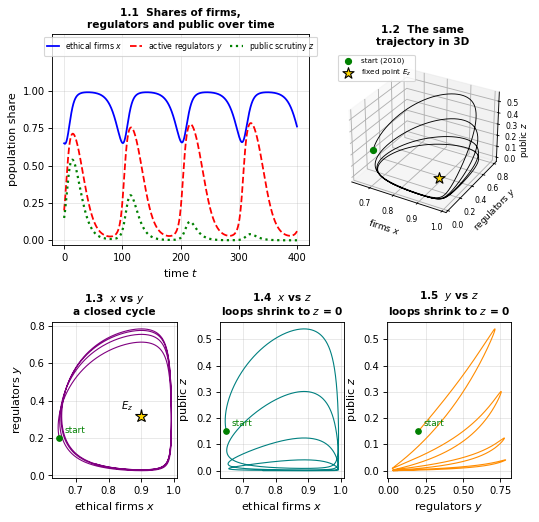

In [4]:
X0 = (0.65, 0.20, 0.15)            # 2010 row of the indices
t1 = np.linspace(0, 400, 4001)     # 400 time units = about four cycles
sol1 = egt.simulate(X0, t1, k=K0)
pk, _ = find_peaks(sol1[:, 1])
print("spacing of regulator peaks:", np.round(np.diff(t1[pk]), 1))
print("public scrutiny at each regulator peak:", np.round(sol1[pk, 2], 3))

fig1 = plt.figure(figsize=(TEXTW, 7.2))
outer1 = gridspec.GridSpec(2, 1, figure=fig1, hspace=0.42, height_ratios=[1.35, 1])
top1 = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=outer1[0], wspace=0.12, width_ratios=[1.45, 1])
bot1 = gridspec.GridSpecFromSubplotSpec(1, 3, subplot_spec=outer1[1], wspace=0.34)
ax = fig1.add_subplot(top1[0])
ax.plot(t1, sol1[:, 0], "b-", label="ethical firms $x$")
ax.plot(t1, sol1[:, 1], "r--", label="active regulators $y$")
ax.plot(t1, sol1[:, 2], "g:", lw=2, label="public scrutiny $z$")
ax.set_title("1.1  Shares of firms, regulators and public over time"); ax.set_xlabel("time $t$"); ax.set_ylabel("population share")
ax.set_ylim(-0.03, 1.38); ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
ax.legend(loc="upper center", ncol=3, fontsize=7, handlelength=1.6, columnspacing=0.9, borderaxespad=0.3)
ax3 = fig1.add_subplot(top1[1], projection="3d")
ax3.plot(*sol1.T, "k-", lw=0.8)
ax3.scatter(*X0, c="g", s=30, label="start (2010)")
ax3.scatter(*Ez, c="gold", s=110, marker="*", edgecolor="k", label="fixed point $E_z$")
ax3.set_title("1.2  The same trajectory in 3D")
ax3.set_xlabel("firms $x$", fontsize=8, labelpad=-1); ax3.set_ylabel("regulators $y$", fontsize=8, labelpad=-1)
ax3.set_zlabel(""); ax3.text2D(1.04, 0.5, "public $z$", transform=ax3.transAxes, rotation=90, va="center", fontsize=8)   # z label placed by hand; hidden at this view angle
ax3.tick_params(labelsize=7, pad=0); ax3.set_box_aspect(None, zoom=0.95)
ax3.legend(loc="upper left", bbox_to_anchor=(0.0, 1.0), fontsize=6.5, frameon=True)
for j, (a, b, la, lb, title, col) in enumerate([(0, 1, "ethical firms $x$", "regulators $y$", "1.3  $x$ vs $y$\na closed cycle", "purple"),
                                                (0, 2, "ethical firms $x$", "public $z$", "1.4  $x$ vs $z$\nloops shrink to $z$ = 0", "teal"),
                                                (1, 2, "regulators $y$", "public $z$", "1.5  $y$ vs $z$\nloops shrink to $z$ = 0", "darkorange")]):
    axp = fig1.add_subplot(bot1[j])
    axp.plot(sol1[:, a], sol1[:, b], color=col, lw=1)
    axp.plot(X0[a], X0[b], "o", color="g", ms=5)
    axp.annotate("start", (X0[a], X0[b]), xytext=(5, 5), textcoords="offset points", fontsize=8, color="g")
    if j == 0:   # E_z is the center of the x-y loops
        axp.plot(Ez[0], Ez[1], "*", color="gold", ms=12, mec="k")
        axp.annotate("$E_z$", (Ez[0], Ez[1]), xytext=(-18, 6), textcoords="offset points", fontsize=9)
    axp.set_title(title); axp.set_xlabel(la); axp.set_ylabel(lb)
save(fig1, "fig1.png")

## 4. Figure 2: many trajectories

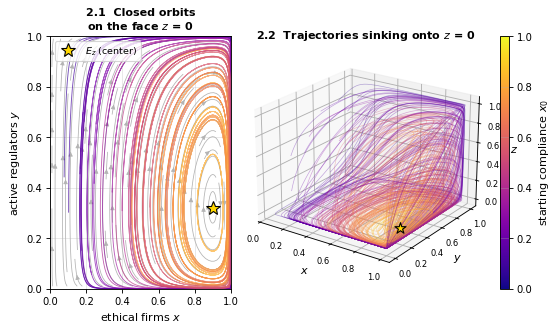

In [5]:
rng = np.random.default_rng(42)
fig2 = plt.figure(figsize=(TEXTW, 4.1))
gs2 = gridspec.GridSpec(1, 3, figure=fig2, width_ratios=[1, 1.3, 0.05], wspace=0.12)
ax = fig2.add_subplot(gs2[0, 0])
Yg, Xg = np.mgrid[0.01:0.99:24j, 0.01:0.99:24j]
U = np.zeros_like(Xg); V = np.zeros_like(Yg)
for i in range(24):
    for j in range(24):
        U[i, j], V[i, j], _ = egt.rhs([Xg[i, j], Yg[i, j], 0.0], 0, p, K0)
ax.streamplot(Xg, Yg, U, V, color="0.7", density=1.2, linewidth=0.7, arrowsize=0.8)
t2 = np.linspace(0, 300, 1500)      # longer than one period, so every orbit closes
cmap2 = plt.cm.plasma
for x0, y0 in rng.uniform(0.05, 0.95, size=(40, 2)):   # 40 random starts
    s = egt.simulate((x0, y0, 0.0), t2, k=K0)
    ax.plot(s[:, 0], s[:, 1], color=cmap2(x0), alpha=0.7, lw=0.8)
ax.plot(Ez[0], Ez[1], "*", color="gold", ms=13, mec="k", zorder=10, label="$E_z$ (center)")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(loc="upper left")
ax.set_title("2.1  Closed orbits on the face $z$ = 0"); ax.set_xlabel("ethical firms $x$"); ax.set_ylabel("active regulators $y$")
ax = fig2.add_subplot(gs2[0, 1], projection="3d")
t2b = np.linspace(0, 600, 2400)     # long enough to see z shrink toward 0
for x0, y0, z0 in rng.uniform(0.05, 0.95, size=(60, 3)):   # 60 random starts
    s = egt.simulate((x0, y0, z0), t2b, k=K0)
    ax.plot(*s.T, color=cmap2(x0), alpha=0.35, lw=0.6)
ax.scatter(*Ez, c="gold", s=110, marker="*", edgecolor="k", depthshade=False)
ax.set_title("2.2  Trajectories sinking onto $z$ = 0"); ax.set_xlabel("$x$", labelpad=-2); ax.set_ylabel("$y$", labelpad=-2); ax.set_zlabel("$z$", labelpad=-2)
ax.tick_params(labelsize=7.5, pad=0); ax.view_init(elev=22, azim=-55); ax.set_box_aspect(None, zoom=1.05)
cax = fig2.add_subplot(gs2[0, 2])
fig2.colorbar(plt.cm.ScalarMappable(cmap=cmap2), cax=cax, label="starting compliance $x_0$")
save(fig2, "fig2.png")

## 5. Figure 3: noise, path dependence, delay
The noise level and shock scale are illustrative (Sec. 2.7 of the paper); they are not fitted.

x(150): min 0.367, median 0.992, max 1.000
shocks: mean 1.003, median 0.894, skew 1.80, excess kurtosis 6.20
S** = 0.299, S* = 0.399
first S with x(150) > 0.9: corrupt start 0.35000000000000003 | ethical start 0.325
second y peak: delay 0.91 vs none 0.76; x trough after it: delay 0.55 vs none 0.65; max |dx| = 0.34


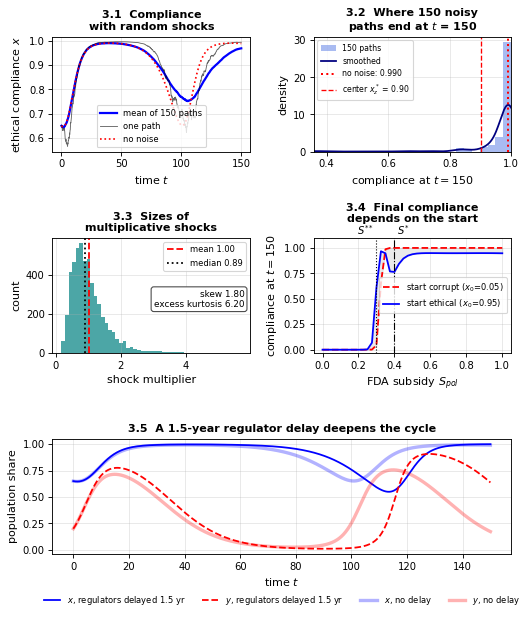

In [6]:
rng = np.random.default_rng(7)
VOL = 0.08                 # noise amplitude (illustrative)
NPATH, NSTEP, TEND = 150, 1000, 150.0   # dt = 0.15
dt = TEND / NSTEP; tt3 = np.linspace(0, TEND, NSTEP)
paths = np.zeros((NPATH, NSTEP))
for n in range(NPATH):
    s = np.array(X0, float); paths[n, 0] = s[0]
    for i in range(1, NSTEP):
        d = np.array(egt.rhs(s, 0, p, K0))
        noise = VOL * s[0] * (1 - s[0]) * np.sqrt(dt) * rng.standard_normal()
        s = np.clip(s + d * dt + np.array([noise, 0, 0]), 1e-6, 1 - 1e-6)  # keep shares inside (0, 1)
        paths[n, i] = s[0]
det3 = egt.simulate(X0, tt3, k=K0)[:, 0]

fig3 = plt.figure(figsize=(TEXTW, 8.4))
gs3 = gridspec.GridSpec(3, 2, figure=fig3, wspace=0.32, hspace=0.75)
ax = fig3.add_subplot(gs3[0, 0])
ax.plot(tt3, paths.mean(0), "b-", lw=2, label="mean of 150 paths")
ax.plot(tt3, paths[0], "k-", alpha=0.6, lw=0.8, label="one path")
ax.plot(tt3, det3, "r:", lw=1.5, label="no noise")
ax.set_title("3.1  Compliance with random shocks"); ax.set_xlabel("time $t$"); ax.set_ylabel("ethical compliance $x$")
ax.legend(fontsize=7.5, loc="lower center")

xT = paths[:, -1]
ax = fig3.add_subplot(gs3[0, 1])
lo = max(0.0, xT.min() - 0.01)
ax.hist(xT, bins=25, range=(lo, 1.0), density=True, color="royalblue", alpha=0.45, label="150 paths")
grid = np.linspace(lo, 1.0, 300); ax.plot(grid, gaussian_kde(xT)(grid), color="navy", label="smoothed")
ax.axvline(det3[-1], color="red", ls=":", lw=1.8, label=f"no noise: {det3[-1]:.3f}")
ax.axvline(XZ, color="red", ls="--", lw=1.2, label=f"center $x_z^*$ = {XZ:.2f}")
ax.set_xlim(lo, 1.0)
ax.set_title("3.2  Where 150 noisy paths end at $t$ = 150"); ax.set_xlabel("compliance at $t=150$"); ax.set_ylabel("density")
ax.legend(fontsize=7, loc="upper left")
print(f"x(150): min {xT.min():.3f}, median {np.median(xT):.3f}, max {xT.max():.3f}")

rng = np.random.default_rng(11)
SIG_SHOCK = 0.5            # log-normal shape parameter, illustrative
shocks = rng.lognormal(mean=-0.5 * SIG_SHOCK**2, sigma=SIG_SHOCK, size=5000)   # mean 1
mn, md, sk, ku = shocks.mean(), np.median(shocks), skew(shocks), kurtosis(shocks)
ax = fig3.add_subplot(gs3[1, 0])
ax.hist(shocks, bins=50, color="teal", alpha=0.7)
ax.axvline(mn, color="red", ls="--", label=f"mean {mn:.2f}")
ax.axvline(md, color="k", ls=":", label=f"median {md:.2f}")
ax.text(0.97, 0.55, f"skew {sk:.2f}\nexcess kurtosis {ku:.2f}", transform=ax.transAxes, ha="right", va="top",
        fontsize=8, bbox=dict(boxstyle="round", fc="white", ec="0.3"))
ax.set_title("3.3  Sizes of multiplicative shocks"); ax.set_xlabel("shock multiplier"); ax.set_ylabel("count"); ax.legend(fontsize=7.5, loc="upper right")
print(f"shocks: mean {mn:.3f}, median {md:.3f}, skew {sk:.2f}, excess kurtosis {ku:.2f}")

S_range = np.linspace(0, 1.0, 41)   # steps of 0.025 in S
x_from_low = [egt.simulate((0.05, 0.2, 0.2), [0, 150], k=KBAR, S_pol=s)[-1, 0] for s in S_range]
x_from_high = [egt.simulate((0.95, 0.2, 0.2), [0, 150], k=KBAR, S_pol=s)[-1, 0] for s in S_range]
S_2star = KBAR**3 - p["alpha"] - (p["gamma"] - p["C_base"])   # subsidy where kbar = k**
S_star = KBAR**3 + p["C_base"] - p["alpha"]                     # subsidy where kbar = k*
ax = fig3.add_subplot(gs3[1, 1])
ax.plot(S_range, x_from_low, "r--", label="start corrupt ($x_0$=0.05)")
ax.plot(S_range, x_from_high, "b-", label="start ethical ($x_0$=0.95)")
ax.fill_between(S_range, x_from_low, x_from_high, color="0.6", alpha=0.2)
for sv, ls, lab, ha in [(S_2star, ":", "$S^{**}$ ", "right"), (S_star, "-.", " $S^{*}$", "left")]:
    ax.axvline(sv, color="k", ls=ls, lw=1); ax.text(sv, 1.13, lab, ha=ha, fontsize=9)
ax.set_ylim(-0.03, 1.1)
ax.set_title("3.4  Final compliance depends on the start", pad=14); ax.set_xlabel("FDA subsidy $S_{pol}$"); ax.set_ylabel("compliance at $t=150$")
ax.legend(fontsize=7.5, loc="center right")
print(f"S** = {S_2star:.3f}, S* = {S_star:.3f}")
xl, xh = np.array(x_from_low), np.array(x_from_high)
print("first S with x(150) > 0.9: corrupt start", S_range[np.argmax(xl > 0.9)], "| ethical start", S_range[np.argmax(xh > 0.9)])

TAU = 1.5                  # regulator delay in years (Sec. 2.7)
lag = max(1, int(round(TAU / dt)))
hist = np.zeros((NSTEP, 3)); hist[0] = X0
c = egt.coefficients(p, K0)
for i in range(1, NSTEP):
    x, y, z = hist[i - 1]; x_lag = hist[max(0, i - lag), 0]
    hist[i, 0] = x + x * (1 - x) * (c["a0"] + c["ay"] * y + c["az"] * z) * dt
    hist[i, 1] = y + y * (1 - y) * (c["b0"] + c["bx"] * x_lag) * dt      # regulators see old x
    hist[i, 2] = z + z * (1 - z) * (c["c0"] + c["cx"] * x) * dt
nodelay = egt.simulate(X0, tt3, k=K0)
ax = fig3.add_subplot(gs3[2, :])
ax.plot(tt3, hist[:, 0], "b-", label="$x$, regulators delayed 1.5 yr")
ax.plot(tt3, hist[:, 1], "r--", label="$y$, regulators delayed 1.5 yr")
ax.plot(tt3, nodelay[:, 0], "b-", alpha=0.3, lw=3, label="$x$, no delay")
ax.plot(tt3, nodelay[:, 1], "r-", alpha=0.3, lw=3, label="$y$, no delay")
ax.set_title("3.5  A 1.5-year regulator delay deepens the cycle"); ax.set_xlabel("time $t$"); ax.set_ylabel("population share")
ax.legend(fontsize=7.5, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.28), frameon=False)
save(fig3, "fig3.png")
pk_d, _ = find_peaks(hist[:, 1]); pk_n, _ = find_peaks(nodelay[:, 1])
print(f"second y peak: delay {hist[pk_d[-1], 1]:.2f} vs none {nodelay[pk_n[-1], 1]:.2f}; "
      f"x trough after it: delay {hist[400:, 0].min():.2f} vs none {nodelay[400:, 0].min():.2f}; "
      f"max |dx| = {np.max(np.abs(hist[:, 0] - nodelay[:, 0])):.2f}")

## 6. Figure 4: policy levers and sensitivity
All runs use the 2010-2024 mean friction kbar = 0.7975, which lies between k* and k**.

x(150) by alpha: {0.1: np.float64(0.0), 0.3: np.float64(1.0), 0.6: np.float64(1.0), 0.9: np.float64(1.0)}
x(150) by gamma: {0.1: np.float64(0.68), 0.2: np.float64(1.0), 0.5: np.float64(1.0), 0.85: np.float64(1.0), 1.2: np.float64(1.0)}
S = 0.1: E_z = [ 0.9   -0.501  0.   ], x range over t<=400 [0.00, 0.50], final [0. 1. 1.]
S = 0.4: E_z = [0.9   0.994 0.   ], x range over t<=400 [0.50, 1.00], final [0.991 0.997 0.625]
S = 0.8: E_z = [0.9 0.2 0. ], x range over t<=400 [0.42, 1.00], final [0.867 0.001 0.   ]
           parameter    +20%    -20%
0       $C_r$ = 0.10 -0.0052  0.0005
1       $B_r$ = 1.00 -0.0000 -0.0071
2       $B_p$ = 0.90  0.0530 -0.0319
3       $C_p$ = 0.10 -0.0261  0.0917
4    $\gamma$ = 0.10  0.0246 -0.2896
5  $C_{base}$ = 0.10 -0.2982  0.0263
6    $\alpha$ = 0.21 -0.0046 -0.8685
7   $S_{pol}$ = 0.32  0.0513 -0.8710
8         $k$ = 0.80 -0.8710  0.0319


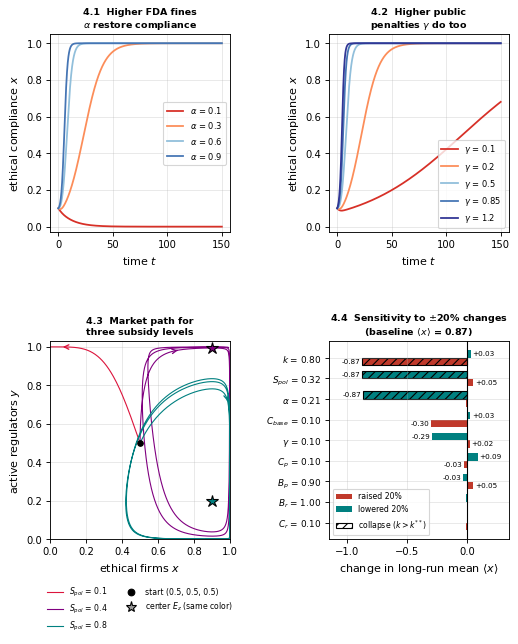

In [7]:
t4 = np.linspace(0, 150, 1500)
fig4 = plt.figure(figsize=(TEXTW, 8.2))
gs4 = gridspec.GridSpec(2, 2, figure=fig4, wspace=0.55, hspace=0.55)
cols = ["#d73027", "#fc8d59", "#91bfdb", "#4575b4", "#313695"]
start4 = (0.1, 0.2, 0.2)          # a market that starts mostly non-compliant
ax = fig4.add_subplot(gs4[0, 0])
for i, a in enumerate([0.1, 0.3, 0.6, 0.9]):   # one value below the fitted 0.21, three above
    ax.plot(t4, egt.simulate(start4, t4, k=KBAR, alpha=a)[:, 0], color=cols[i], label=f"$\\alpha$ = {a}")
ax.set_title("4.1  Higher FDA fines $\\alpha$ restore compliance"); ax.set_xlabel("time $t$"); ax.set_ylabel("ethical compliance $x$")
ax.set_ylim(-0.03, 1.05); ax.legend(fontsize=7.5, loc="center right")
ax = fig4.add_subplot(gs4[0, 1])
for i, g in enumerate([0.1, 0.2, 0.5, 0.85, 1.2]):
    ax.plot(t4, egt.simulate(start4, t4, k=KBAR, gamma=g)[:, 0], color=cols[i], label=f"$\\gamma$ = {g}")
ax.set_title("4.2  Higher public penalties $\\gamma$ do too"); ax.set_xlabel("time $t$"); ax.set_ylabel("ethical compliance $x$")
ax.set_ylim(-0.03, 1.05); ax.legend(fontsize=7.5, loc="lower right")
print("x(150) by alpha:", {a: round(egt.simulate(start4, [0, 150], k=KBAR, alpha=a)[-1, 0], 3) for a in [0.1, 0.3, 0.6, 0.9]})
print("x(150) by gamma:", {g: round(egt.simulate(start4, [0, 150], k=KBAR, gamma=g)[-1, 0], 3) for g in [0.1, 0.2, 0.5, 0.85, 1.2]})

# 4.3: the path in the firm-regulator plane for three subsidy levels, from (0.5, 0.5, 0.5)
ax = fig4.add_subplot(gs4[1, 0])
t43 = np.linspace(0, 400, 4000)   # 2+ cycles
scol = ["crimson", "purple", "teal"]
for i, s in enumerate([0.1, 0.4, 0.8]):
    sol = egt.simulate((0.5, 0.5, 0.5), t43, k=KBAR, S_pol=s)
    ax.plot(sol[:, 0], sol[:, 1], color=scol[i], lw=1, label=f"$S_{{pol}}$ = {s}")
    for idx in (120,):            # direction arrow
        ax.annotate("", xy=sol[idx + 15, :2], xytext=sol[idx, :2], arrowprops=dict(arrowstyle="->", color=scol[i], lw=1.2))
    fp = egt.face_fixed_points(egt.P(S_pol=s), KBAR)["z=0"]
    if 0 < fp[1] < 1:
        ax.plot(fp[0], fp[1], "*", ms=11, color=scol[i], mec="k", zorder=6)
    print(f"S = {s}: E_z = {np.round(fp, 3)}, x range over t<=400 [{sol[:, 0].min():.2f}, {sol[:, 0].max():.2f}], final {np.round(sol[-1], 3)}")
ax.plot(0.5, 0.5, "ko", ms=5, zorder=7)
handles = ax.get_legend_handles_labels()[0] + [Line2D([], [], marker="o", ls="", color="k", label="start (0.5, 0.5, 0.5)"),
                                                Line2D([], [], marker="*", ls="", color="0.6", mec="k", ms=10, label="center $E_z$ (same color)")]
ax.legend(handles=handles, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.03)
ax.set_title("4.3  Market path for three subsidy levels"); ax.set_xlabel("ethical firms $x$"); ax.set_ylabel("active regulators $y$")

# 4.4: one-at-a-time +-20% changes; each run is summarized by its long-run mean compliance
base = egt.long_run_mean_x(k=KBAR)
names44 = [("B_r", "$B_r$"), ("B_p", "$B_p$"), ("C_r", "$C_r$"), ("C_p", "$C_p$"), ("gamma", "$\\gamma$"),
           ("alpha", "$\\alpha$"), ("S_pol", "$S_{pol}$"), ("C_base", "$C_{base}$"), ("k", "$k$")]
tor = []
for key, lab in names44:
    v0 = KBAR if key == "k" else p[key]
    if key == "k":
        up, dn = egt.long_run_mean_x(k=KBAR * 1.2), egt.long_run_mean_x(k=KBAR * 0.8)
    else:
        up = egt.long_run_mean_x(k=KBAR, **{key: v0 * 1.2}); dn = egt.long_run_mean_x(k=KBAR, **{key: v0 * 0.8})
    tor.append((f"{lab} = {v0:.2f}", up - base, dn - base))
tor.sort(key=lambda r: max(abs(r[1]), abs(r[2])))
ax = fig4.add_subplot(gs4[1, 1])
yy = np.arange(len(tor))
for off, idx, col, lab in [(-0.19, 1, "#C0392B", "raised 20%"), (0.19, 2, "#008080", "lowered 20%")]:
    vals = np.array([r[idx] for r in tor])
    bars = ax.barh(yy + off, vals, height=0.36, color=col, label=lab)
    for b_, v_ in zip(bars, vals):
        if v_ < -0.5: b_.set_hatch("///"); b_.set_edgecolor("k")     # these runs collapse (cross k**)
        if abs(v_) >= 0.01:      # skip labels below 0.01
            ax.text(v_ + (0.015 if v_ >= 0 else -0.015), b_.get_y() + b_.get_height() / 2, f"{v_:+.2f}",
                    va="center", ha="left" if v_ >= 0 else "right", fontsize=6.5)
ax.set_yticks(yy); ax.set_yticklabels([r[0] for r in tor], fontsize=8)
ax.axvline(0, color="k", lw=1); ax.set_xlim(-1.15, 0.35)
ax.legend(handles=ax.get_legend_handles_labels()[0] + [Patch(facecolor="w", edgecolor="k", hatch="///", label="collapse ($k>k^{**}$)")],
          fontsize=7, loc="lower left")
ax.set_title(f"4.4  Sensitivity to $\\pm$20% changes\n(baseline $\\langle x\\rangle$ = {base:.2f})"); ax.set_xlabel("change in long-run mean $\\langle x\\rangle$")
display(pd.DataFrame(tor, columns=["parameter", "+20%", "-20%"]).round(4))
save(fig4, "fig4.png")

## 7. Figure 5: two-parameter maps
Each pixel is one run from (0.5, 0.5, 0.5), colored by the long-run mean compliance over
200 <= t <= 500 (as in Panel 4.4). White lines: analytic thresholds. Black lines: <x> = 0.5
(dashed) and 0.8 (dotted). 5.6 also marks C_r = B_r C_p / B_p and C_r = B_r.

S-k  : share with <x> > 0.5 = 0.63 | <x> in surviving part [0.75, 0.98]
S-g  : share with <x> > 0.5 = 0.96 | <x> in surviving part [0.83, 0.98]
k-a  : share with <x> > 0.5 = 0.66 | <x> in surviving part [0.79, 0.98]
g-a  : share with <x> > 0.5 = 0.98 | <x> in surviving part [0.83, 0.98]
k-C  : share with <x> > 0.5 = 0.18 | <x> in surviving part [0.75, 1.00]
S-Cr : share with <x> > 0.5 = 0.73 | <x> in surviving part [0.50, 1.00]
5.6: <x> below C_r=0.113: [0.85, 1.00]; between: [0.47, 0.92]; above C_r=B_r: [0.46, 0.70]


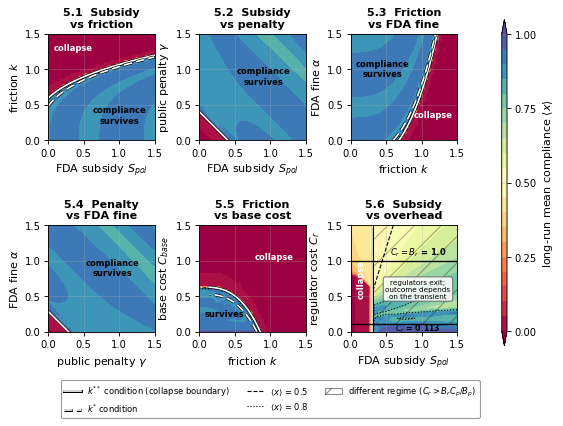

In [8]:
def heat(ax, n1, n2, l1, l2, title, r1=(0.0, 1.5), r2=(0.0, 1.5), N=41, curves=(), labels=()):
    # all axes 0-1.5; 41x41 grid
    g1, g2 = np.linspace(*r1, N), np.linspace(*r2, N)
    Z = np.zeros((N, N))
    for i, b in enumerate(g2):
        for j, a in enumerate(g1):
            kw = {n1: a, n2: b}; k = kw.pop("k", KBAR)
            Z[i, j] = egt.long_run_mean_x(k=k, **kw)
    im = ax.contourf(g1, g2, Z, levels=np.linspace(0, 1, 21), cmap="Spectral", extend="both")
    ax.contour(g1, g2, Z, levels=[0.5], colors="k", linestyles="--", linewidths=1.0)
    ax.contour(g1, g2, Z, levels=[0.8], colors="k", linestyles=":", linewidths=1.0)
    for n_, (fx, fy) in enumerate(curves):
        ax.plot(fx, fy, color="w", lw=1.5, ls="-" if n_ == 0 else (0, (5, 2.5)), path_effects=[pe.Stroke(linewidth=2.7, foreground="k"), pe.Normal()])   # white line with black edge
    for lab in labels:                # region labels
        tx, ty, txt = lab[:3]; rot = lab[3] if len(lab) > 3 else 0
        ax.text(tx, ty, txt, ha="center", va="center", fontsize=7.5, rotation=rot,
                color="w" if "collapse" in txt else "k", fontweight="bold")
    ax.set_xlim(*r1); ax.set_ylim(*r2); ax.grid(True, alpha=0.3); ax.set_box_aspect(1)   # square panels
    ax.set_xticks(np.linspace(r1[0], r1[1], 4))   # 0, 0.5, 1.0, 1.5 on every panel
    ax.set_title(title); ax.set_xlabel(l1); ax.set_ylabel(l2)
    return im, Z

Sa, C0, al0, g0, S0 = p["S_pol"] + p["alpha"], p["C_base"], p["alpha"], p["gamma"], p["S_pol"]
D = g0 - C0          # 0 for the fitted constants (gamma = C_base)
CR_SWAP = p["B_r"] * p["C_p"] / p["B_p"]   # 0.113: above it C_r/B_r > C_p/B_p and regulators exit
kk = np.linspace(0.0, 1.5, 600); gg = np.linspace(0.0, 1.5, 600)
inb = lambda a, b, ra=(0.0, 1.5), rb=(0.0, 1.5): (a >= ra[0]) & (a <= ra[1]) & (b >= rb[0]) & (b <= rb[1])
fig5 = plt.figure(figsize=(TEXTW, 5.3))
gs5 = gridspec.GridSpec(2, 4, figure=fig5, width_ratios=[1, 1, 1, 0.05], wspace=0.55, hspace=0.42)
maps = {}
s2, s1 = kk**3 - al0 - D, kk**3 + C0 - al0
im, maps["S-k"] = heat(fig5.add_subplot(gs5[0, 0]), "S_pol", "k", "FDA subsidy $S_{pol}$", "friction $k$", "5.1  Subsidy vs friction",
                      curves=[(s2[inb(s2, kk)], kk[inb(s2, kk)]), (s1[inb(s1, kk)], kk[inb(s1, kk)])],
                      labels=[(0.35, 1.3, "collapse"), (1.0, 0.35, "compliance\nsurvives")])
gl = KBAR**3 + C0 - al0 - gg
im, maps["S-g"] = heat(fig5.add_subplot(gs5[0, 1]), "S_pol", "gamma", "FDA subsidy $S_{pol}$", "public penalty $\\gamma$", "5.2  Subsidy vs penalty",
                      curves=[(gl[inb(gl, gg)], gg[inb(gl, gg)])], labels=[(0.9, 0.9, "compliance\nsurvives")])
a2, a1 = kk**3 - S0 - D, kk**3 + C0 - S0
im, maps["k-a"] = heat(fig5.add_subplot(gs5[0, 2]), "k", "alpha", "friction $k$", "FDA fine $\\alpha$", "5.3  Friction vs FDA fine",
                      curves=[(kk[inb(kk, a2)], a2[inb(kk, a2)]), (kk[inb(kk, a1)], a1[inb(kk, a1)])],
                      labels=[(1.17, 0.35, "collapse"), (0.45, 1.0, "compliance\nsurvives")])
al_ = KBAR**3 + C0 - S0 - gg
im, maps["g-a"] = heat(fig5.add_subplot(gs5[1, 0]), "gamma", "alpha", "public penalty $\\gamma$", "FDA fine $\\alpha$", "5.4  Penalty vs FDA fine",
                      curves=[(gg[inb(gg, al_)], al_[inb(gg, al_)])], labels=[(0.9, 0.9, "compliance\nsurvives")])
cc = np.linspace(0.0, 1.5, 600)
k2c, k1c = np.cbrt(np.clip(Sa + g0 - cc, 0, None)), np.cbrt(np.clip(Sa - cc, 0, None))
m2, m1 = (Sa + g0 - cc) > 1e-3, (Sa - cc) > 1e-3
im, maps["k-C"] = heat(fig5.add_subplot(gs5[1, 1]), "k", "C_base", "friction $k$", "base cost $C_{base}$", "5.5  Friction vs base cost",
                      curves=[(k2c[m2], cc[m2]), (k1c[m1], cc[m1])],
                      labels=[(1.05, 1.05, "collapse"), (0.35, 0.25, "survives")])
ax56 = fig5.add_subplot(gs5[1, 2])
im, maps["S-Cr"] = heat(ax56, "S_pol", "C_r", "FDA subsidy $S_{pol}$", "regulator cost $C_r$", "5.6  Subsidy vs overhead",
                       curves=[(np.full(2, S_2star), np.array([0.0, 1.5]))], labels=[(0.15, 0.75, "collapse", 90)])
ax56.axhspan(CR_SWAP, 1.5, xmin=S_2star / 1.5, facecolor="none", edgecolor=(0, 0, 0, 0.3), hatch="/", lw=0)
ax56.axhline(CR_SWAP, color="k", lw=1.2)
ax56.text(0.95, CR_SWAP / 2, f"$C_r$ = {CR_SWAP:.3f}", fontsize=7, ha="center", va="center", fontweight="bold")
ax56.axhline(p["B_r"], color="k", lw=1.2)   # C_r = B_r
ax56.text(0.95, p["B_r"] + 0.03, f"$C_r = B_r$ = {p['B_r']:.1f}", fontsize=7.5, ha="center", va="bottom", fontweight="bold")
ax56.text(0.95, 0.6, "regulators exit;\noutcome depends\non the transient", fontsize=6.5, ha="center", va="center",
          bbox=dict(boxstyle="round", fc="white", ec="0.4", alpha=0.85))
cax5 = fig5.add_subplot(gs5[:, 3]); fig5.colorbar(im, cax=cax5, label="long-run mean compliance $\\langle x\\rangle$", ticks=[0, 0.25, 0.5, 0.75, 1.0])
fig5.legend(handles=[Line2D([], [], color="w", lw=1.5, path_effects=[pe.Stroke(linewidth=2.7, foreground="k"), pe.Normal()], label="$k^{**}$ condition (collapse boundary)"),
                     Line2D([], [], color="w", lw=1.5, ls=(0, (5, 2.5)), path_effects=[pe.Stroke(linewidth=2.7, foreground="k"), pe.Normal()], label="$k^{*}$ condition"),
                     Line2D([], [], color="k", ls="--", lw=1.0, label="$\\langle x\\rangle$ = 0.5"), Line2D([], [], color="k", ls=":", lw=1.0, label="$\\langle x\\rangle$ = 0.8"),
                     Patch(facecolor="none", edgecolor=(0, 0, 0, 0.45), hatch="/", label="different regime ($C_r > B_r C_p/B_p$)")],
            loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.07), facecolor="white", edgecolor="0.6", framealpha=1, fontsize=7.5)
save(fig5, "fig5.png")
for key, Z in maps.items():
    surv = Z[Z > 0.5]
    print(f"{key:5s}: share with <x> > 0.5 = {np.mean(Z > 0.5):.2f} | <x> in surviving part [{surv.min():.2f}, {surv.max():.2f}]")
Zc = maps["S-Cr"]; g2c = np.linspace(0.0, 1.5, 41); g1c = np.linspace(0.0, 1.5, 41)
below = Zc[(g2c < CR_SWAP)][:, g1c > S_2star + 0.03]; above = Zc[(g2c > CR_SWAP)][:, g1c > S_2star + 0.03]
mid = Zc[(g2c > CR_SWAP) & (g2c < p["B_r"])][:, g1c > S_2star + 0.03]; top = Zc[g2c > p["B_r"]][:, g1c > S_2star + 0.03]
print(f"5.6: <x> below C_r={CR_SWAP:.3f}: [{below.min():.2f}, {below.max():.2f}]; between: [{mid.min():.2f}, {mid.max():.2f}]; above C_r=B_r: [{top.min():.2f}, {top.max():.2f}]")

## 8. Figure 6: spatial lattice
Nowak-May style: each cell plays its 8 neighbors (Moore neighborhood), ethical cells get 1
per ethical neighbor, defectors get b per ethical neighbor, then every cell copies the best
scorer around it (itself included). Wrap-around edges. b = 1.65 is inside the 1 < b < 2 range
Nowak and May looked at; 10% starting defectors is illustrative.

ethical share: start 0.898, gen 10 0.357, end 0.290


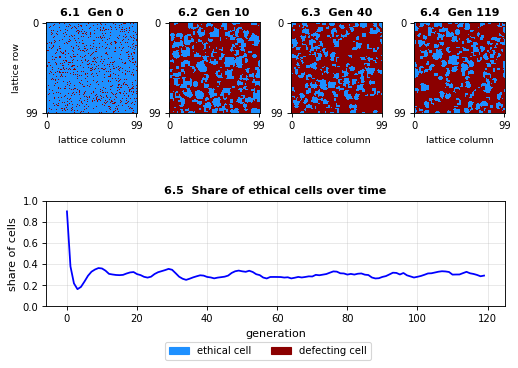

In [9]:
rng = np.random.default_rng(7)
NG, B_DEF, NGEN = 100, 1.65, 120     # 120 generations: the share has settled by ~40
grid = rng.choice([0, 1], size=(NG, NG), p=[0.1, 0.9])
kernel = np.array([[1, 1, 1], [1, 0, 1], [1, 1, 1]])
snaps, dens = [], []
for gen in range(NGEN):
    if gen in (0, 10, 40, NGEN - 1): snaps.append(grid.copy())
    dens.append(grid.mean())
    n_eth = convolve2d(grid, kernel, mode="same", boundary="wrap")
    pay = np.where(grid == 1, n_eth, B_DEF * n_eth).astype(float)
    best_p, best_s = pay.copy(), grid.copy()
    for dx, dy in [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]:
        sp, sg = np.roll(pay, (dx, dy), axis=(0, 1)), np.roll(grid, (dx, dy), axis=(0, 1))
        better = sp > best_p; best_p[better] = sp[better]; best_s[better] = sg[better]
    grid = best_s
fig6 = plt.figure(figsize=(TEXTW, 4.9))
gs6 = gridspec.GridSpec(2, 4, figure=fig6, hspace=0.6, wspace=0.35, height_ratios=[1.2, 1])
cmap6 = ListedColormap(["#8B0000", "#1E90FF"])
for i, (st, gen) in enumerate(zip(snaps, [0, 10, 40, NGEN - 1])):
    a = fig6.add_subplot(gs6[0, i]); a.imshow(st, cmap=cmap6, interpolation="nearest")
    a.set_title(f"6.{i + 1}  Gen {gen}"); a.set_xticks([0, 99]); a.set_yticks([0, 99]); a.grid(False)
    a.set_xlabel("lattice column", fontsize=8.5); a.set_ylabel("lattice row" if i == 0 else "", fontsize=8.5)
a = fig6.add_subplot(gs6[1, :]); a.plot(dens, "b-")
a.set_ylim(0, 1); a.set_title("6.5  Share of ethical cells over time"); a.set_xlabel("generation"); a.set_ylabel("share of cells")
fig6.legend(handles=[Patch(color="#1E90FF", label="ethical cell"), Patch(color="#8B0000", label="defecting cell")],
            loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.04), fontsize=9)
save(fig6, "fig6.png")
print(f"ethical share: start {dens[0]:.3f}, gen 10 {dens[10]:.3f}, end {dens[-1]:.3f}")

## 9. Figure 7: fit to the data

7.1: R2 = 0.678, MSE = 0.0124
7.2: R2 = 0.948, MSE = 0.0035
7.3: R2 = 0.984, MSE = 0.0011
residuals: {2010: np.float64(0.0), 2012: np.float64(0.076), 2014: np.float64(0.135), 2016: np.float64(0.204), 2018: np.float64(0.162), 2020: np.float64(0.006), 2022: np.float64(-0.08), 2024: np.float64(-0.022)}
projected x in 2030: 0.009


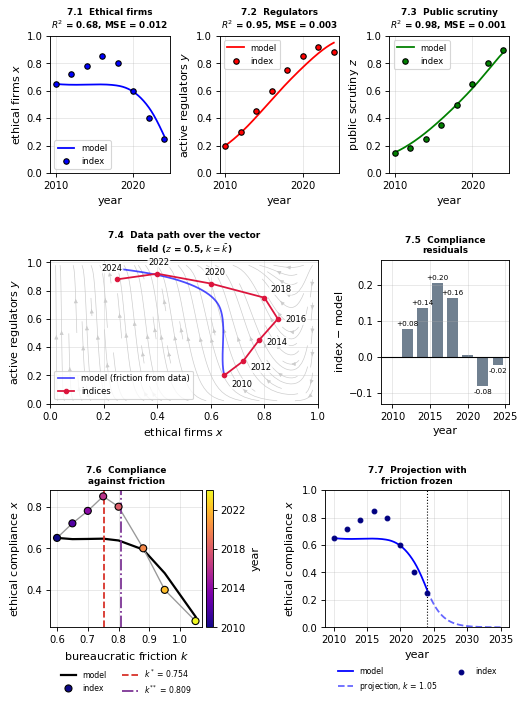

In [10]:
t_fine = np.linspace(0, 14, 1000)
cal = egt.calibrated_path(t_fine); cal_obs = egt.calibrated_path(t_emp)
fig7 = plt.figure(figsize=(TEXTW, 9.6))
outer7 = gridspec.GridSpec(3, 1, figure=fig7, hspace=0.62, height_ratios=[1, 1.05, 1])
row0 = gridspec.GridSpecFromSubplotSpec(1, 3, subplot_spec=outer7[0], wspace=0.42)
row1 = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=outer7[1], wspace=0.32, width_ratios=[2.1, 1])
row2 = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=outer7[2], wspace=0.5)
for j, (obs, col, lab, nm) in enumerate([(x_emp, "b", "ethical firms $x$", "Ethical firms"), (y_emp, "r", "active regulators $y$", "Regulators"),
                                         (z_emp, "g", "public scrutiny $z$", "Public scrutiny")]):
    a = fig7.add_subplot(row0[j])
    a.plot(2010 + t_fine, cal[:, j], col + "-", label="model")
    a.scatter(years, obs, color=col, edgecolor="k", s=24, zorder=5, label="index")
    r2, mse = r2_score(obs, cal_obs[:, j]), mean_squared_error(obs, cal_obs[:, j])
    a.set_ylim(0, 1)            # common 0-1 scale
    a.set_title(f"7.{j+1}  {nm}\n$R^2$ = {r2:.2f}, MSE = {mse:.3f}"); a.set_xlabel("year"); a.set_ylabel(lab)
    a.legend(fontsize=7.5, loc="lower left" if j == 0 else "upper left")
    print(f"7.{j+1}: R2 = {r2:.3f}, MSE = {mse:.4f}")
a = fig7.add_subplot(row1[0])
Yg, Xg = np.mgrid[0.02:0.98:22j, 0.02:0.98:22j]; U = np.zeros_like(Xg); V = np.zeros_like(Yg)
for i in range(22):
    for j in range(22):
        U[i, j], V[i, j], _ = egt.rhs([Xg[i, j], Yg[i, j], 0.5], 0, p, KBAR)
a.streamplot(Xg, Yg, U, V, color="0.8", density=1.0, linewidth=0.6, arrowsize=0.7)
a.plot(cal[:, 0], cal[:, 1], "b-", alpha=0.7, label="model (friction from data)")
a.plot(x_emp, y_emp, "o-", color="crimson", ms=4, label="indices")
YR_OFF = {2010: (6, -10), 2012: (7, -8), 2014: (7, -4), 2016: (7, -3), 2018: (5, 5), 2020: (-6, 8), 2022: (-8, 8), 2024: (-14, 8)}
for i, yr in enumerate(years):
    a.annotate(str(yr), (x_emp[i], y_emp[i]), textcoords="offset points", xytext=YR_OFF[int(yr)], fontsize=7.5,
               bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.8))
a.set_xlim(0, 1); a.set_ylim(0, 1.02)
a.set_title("7.4  Data path over the vector field ($z$ = 0.5, $k=\\bar k$)"); a.set_xlabel("ethical firms $x$"); a.set_ylabel("active regulators $y$")
a.legend(fontsize=7.5, loc="lower left")
a = fig7.add_subplot(row1[1])
res7 = x_emp - cal_obs[:, 0]
a.bar(years, res7, color="slategray", width=1.4); a.axhline(0, color="k", lw=1)
for yr_, r_ in zip(years, res7):
    if abs(r_) > 0.01: a.text(yr_, r_ + (0.008 if r_ >= 0 else -0.008), f"{r_:+.2f}", ha="center", va="bottom" if r_ >= 0 else "top", fontsize=6.5)
a.set_ylim(-0.13, 0.27)
a.set_title("7.5  Compliance residuals"); a.set_xlabel("year"); a.set_ylabel("index $-$ model")
a = fig7.add_subplot(row2[0])
a.plot(k_emp, cal_obs[:, 0], "k-", lw=2, label="model")
a.plot(k_emp, x_emp, "-", color="0.6", lw=1.2)
sc7 = a.scatter(k_emp, x_emp, c=years, cmap="plasma", s=40, edgecolor="k", zorder=5, label="index")
a.axvline(KS, color="#d73027", ls="--", label=f"$k^*$ = {KS:.3f}")
a.axvline(KSS, color="#7b3294", ls="-.", label=f"$k^{{**}}$ = {KSS:.3f}")
cb7 = fig7.colorbar(sc7, ax=a, pad=0.02, label="year"); cb7.set_ticks([2010, 2014, 2018, 2022])
a.set_title("7.6  Compliance against friction"); a.set_xlabel("bureaucratic friction $k$"); a.set_ylabel("ethical compliance $x$")
a.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.24), ncol=2, frameon=False)
a = fig7.add_subplot(row2[1])
t_fc = np.linspace(14, 25, 400)   # 2024 -> 2035
fc = egt.simulate(cal[-1], t_fc - 14, k=k_emp[-1])        # carry on from the 2024 model state, k frozen at 1.05
a.plot(2010 + t_fine, cal[:, 0], "b-", label="model")
a.plot(2010 + t_fc, fc[:, 0], "b--", alpha=0.6, label="projection, $k$ = 1.05")
a.scatter(years, x_emp, color="navy", s=18, zorder=5, label="index")
a.axvline(2024, color="k", ls=":", lw=1)
a.set_ylim(0, 1)
a.set_title("7.7  Projection with friction frozen"); a.set_xlabel("year"); a.set_ylabel("ethical compliance $x$")
a.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.24), ncol=2, frameon=False)
save(fig7, "fig7.png")
print("residuals:", dict(zip(years.tolist(), np.round(res7, 3))))
print(f"projected x in 2030: {np.interp(2030, 2010 + t_fc, fc[:, 0]):.3f}")

## 10. Figure 8: what the data say

dx/dt: {'2010-2012': np.float64(0.035), '2012-2014': np.float64(0.03), '2014-2016': np.float64(0.035), '2016-2018': np.float64(-0.025), '2018-2020': np.float64(-0.1), '2020-2022': np.float64(-0.1), '2022-2024': np.float64(-0.075)}
f_E - f_D: {2010: np.float64(-0.022), 2012: np.float64(-0.006), 2014: np.float64(0.009), 2016: np.float64(-0.001), 2018: np.float64(-0.037), 2020: np.float64(-0.165), 2022: np.float64(-0.322), 2024: np.float64(-0.563)}
                 year  $x$ firms  $y$ regulators  $z$ public  $k$ friction
year            1.000     -0.695           0.971       0.986         0.991
$x$ firms      -0.695      1.000          -0.542      -0.789        -0.777
$y$ regulators  0.971     -0.542           1.000       0.942         0.933
$z$ public      0.986     -0.789           0.942       1.000         0.991
$k$ friction    0.991     -0.777           0.933       0.991         1.000
distance from (0,1,1): {2010: np.float64(1.336), 2012: np.float64(1.296), 2014: np.float64(1.214), 2

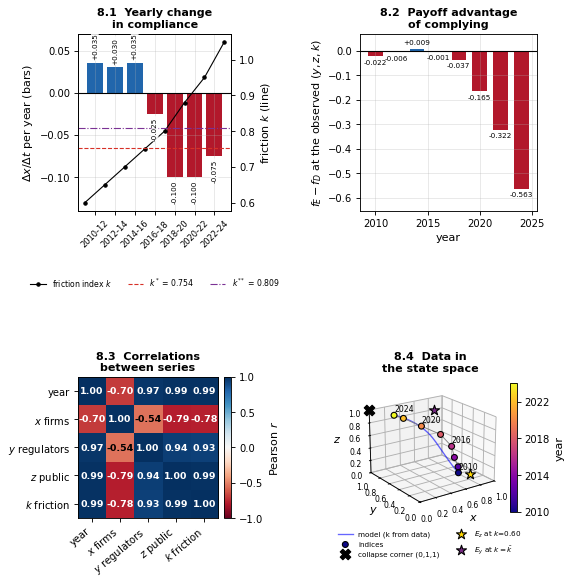

In [11]:
fig8 = plt.figure(figsize=(TEXTW, 8.8))
gs8 = gridspec.GridSpec(2, 2, figure=fig8, wspace=0.78, hspace=0.5, height_ratios=[1, 1.45], width_ratios=[1, 1.15])
a = fig8.add_subplot(gs8[0, 0])
mid = (years[:-1] + years[1:]) / 2; rate = np.diff(x_emp) / np.diff(years)
a.bar(mid, rate, width=1.6, color=np.where(rate < 0, "#b2182b", "#2166ac"))
a.axhline(0, color="k", lw=1); a.set_xticks(mid); a.set_xticklabels([f"{u}-{v % 100:02d}" for u, v in zip(years[:-1], years[1:])], rotation=45, fontsize=7.5)
a.set_ylim(-0.14, 0.07)
a2 = a.twinx(); a2.plot(years, k_emp, "k.-", lw=1, label="friction index $k$"); a2.set_ylabel("friction $k$ (line)"); a2.grid(False)
a2.axhline(KS, color="#d73027", ls="--", lw=1, label=f"$k^*$ = {KS:.3f}"); a2.axhline(KSS, color="#7b3294", ls="-.", lw=1, label=f"$k^{{**}}$ = {KSS:.3f}")
a2.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.33), ncol=3, frameon=False)
for m_, r_ in zip(mid, rate):   # drawn on the twin axis so the labels sit above the friction line
    a2.text(m_, r_ + (0.004 if r_ >= 0 else -0.004), f"{r_:+.3f}", transform=a.transData, ha="center",
            va="bottom" if r_ >= 0 else "top", fontsize=6.5, rotation=90, zorder=10,
            bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.85))
a.set_title("8.1  Yearly change in compliance"); a.set_ylabel("$\\Delta x/\\Delta t$ per year (bars)")
print("dx/dt:", dict(zip([f"{u}-{v}" for u, v in zip(years[:-1], years[1:])], np.round(rate, 3))))
a = fig8.add_subplot(gs8[0, 1])
Femp = -p["C_base"] + (p["S_pol"] + p["alpha"] - k_emp**3) * y_emp + p["gamma"] * z_emp
a.bar(years, Femp, width=1.4, color=np.where(Femp < 0, "#b2182b", "#2166ac"))
for yr_, f_ in zip(years, Femp):
    a.text(yr_, f_ + (0.012 if f_ >= 0 else -0.012), f"{f_:+.3f}", ha="center", va="bottom" if f_ >= 0 else "top", fontsize=6.5)
a.axhline(0, color="k", lw=1); a.set_ylim(Femp.min() - 0.09, 0.07)
a.set_title("8.2  Payoff advantage of complying"); a.set_xlabel("year"); a.set_ylabel("$f_E - f_D$ at the observed $(y,z,k)$")
print("f_E - f_D:", dict(zip(years.tolist(), np.round(Femp, 3))))
a = fig8.add_subplot(gs8[1, 0])
labels = ["year", "$x$ firms", "$y$ regulators", "$z$ public", "$k$ friction"]
corr = df_emp.drop(columns=["Evolutionary_t"]).corr().values      # Evolutionary_t is just year - 2010
im = a.imshow(corr, cmap="RdBu", vmin=-1, vmax=1)
a.set_xticks(range(5)); a.set_yticks(range(5)); a.set_xticklabels(labels, rotation=40, ha="right"); a.set_yticklabels(labels); a.grid(False)
for i in range(5):
    for j in range(5):
        a.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", fontsize=8.5,
               color="white" if abs(corr[i, j]) > 0.6 else "black", fontweight="bold")
plt.colorbar(im, ax=a, fraction=0.046, pad=0.04, label="Pearson $r$")
a.set_title("8.3  Correlations between series")
display(pd.DataFrame(corr, index=labels, columns=labels).round(3))
a = fig8.add_subplot(gs8[1, 1], projection="3d")
a.plot(cal[:, 0], cal[:, 1], cal[:, 2], "b-", alpha=0.6, lw=1.2, label="model (k from data)")
sc8 = a.scatter(x_emp, y_emp, z_emp, c=years, cmap="plasma", s=28, edgecolor="k", depthshade=False, label="indices")
a.plot(x_emp, y_emp, z_emp, color="0.5", lw=0.8)
for i_ in (0, 3, 5, 7): a.text(x_emp[i_], y_emp[i_], z_emp[i_] + 0.06, str(years[i_]), fontsize=7)
a.scatter(0, 1, 1, marker="X", s=90, color="k", depthshade=False, label="collapse corner (0,1,1)")
a.scatter(*Ez, marker="*", s=90, color="gold", edgecolor="k", depthshade=False, label="$E_z$ at $k$=0.60")
a.scatter(*egt.face_fixed_points(p, KBAR)["y=1"], marker="*", s=90, color="#762a83", edgecolor="k", depthshade=False, label="$E_y$ at $k=\\bar k$")
a.set_xlim(0, 1); a.set_ylim(0, 1); a.set_zlim(0, 1)
a.set_xlabel("$x$", labelpad=-3); a.set_ylabel("$y$", labelpad=-3); a.set_zlabel("$z$", labelpad=-3)
a.tick_params(labelsize=7, pad=0); a.view_init(elev=20, azim=-125); a.set_box_aspect(None, zoom=1.0)
a.legend(fontsize=6.5, loc="upper center", bbox_to_anchor=(0.5, -0.04), ncol=2, frameon=False); a.set_title("8.4  Data in the state space")
cb8 = fig8.colorbar(sc8, ax=a, shrink=0.5, pad=0.06, label="year"); cb8.set_ticks([2010, 2014, 2018, 2022])
d011 = np.sqrt(x_emp**2 + (1 - y_emp)**2 + (1 - z_emp)**2)
print("distance from (0,1,1):", dict(zip(years.tolist(), np.round(d011, 3))))
save(fig8, "fig8.png")

## 11. Figures 9-13: checks on the analysis

x(700) [0.096, 1.000]; mean x [0.872, 0.938]; max z(700) 6.01e-01; share with z(700) > 0.05: 0.018


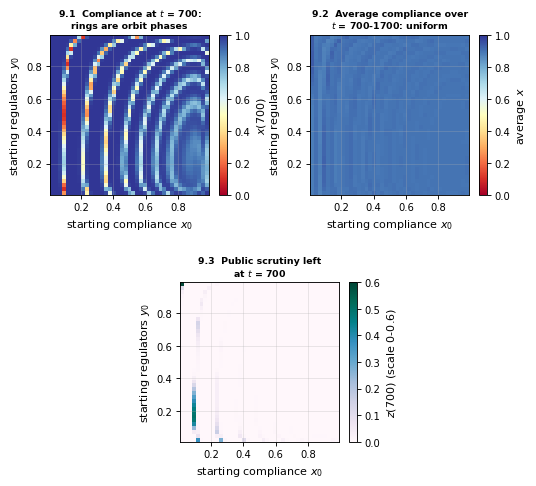

In [12]:
# Figure 9: a 41x41 grid of starting points, z0 = 0.4, k = 0.60
Nb = 41; gb = np.linspace(0.02, 0.98, Nb)   # z0 = 0.4 (arbitrary mid-range value)
t9 = np.concatenate([[0.0], np.linspace(700, 1700, 2001)])   # 6+ cycles
Xterm, Xmean, Zterm = (np.zeros((Nb, Nb)) for _ in range(3))
for i, y0 in enumerate(gb):
    for j, x0 in enumerate(gb):
        s = egt.simulate((x0, y0, 0.4), t9, k=K0)[1:]
        Xterm[i, j], Xmean[i, j], Zterm[i, j] = s[0, 0], s[:, 0].mean(), s[0, 2]
fig9 = plt.figure(figsize=(TEXTW, 6.6))
gs9 = gridspec.GridSpec(2, 4, figure=fig9, hspace=0.55, wspace=0.9)
for cell, Z, cm, ttl, lab, vmax in [(gs9[0, 0:2], Xterm, "RdYlBu", "9.1  Compliance at $t$ = 700:\nrings are orbit phases", "$x(700)$", 1),
                                    (gs9[0, 2:4], Xmean, "RdYlBu", "9.2  Average compliance over\n$t$ = 700-1700: uniform", "average $x$", 1),
                                    (gs9[1, 1:3], Zterm, "PuBuGn", "9.3  Public scrutiny left\nat $t$ = 700", "$z(700)$ (scale 0-0.6)", 0.6)]:
    a = fig9.add_subplot(cell)
    im = a.pcolormesh(gb, gb, Z, cmap=cm, vmin=0, vmax=vmax, shading="auto")
    a.set_title(ttl); a.set_xlabel("starting compliance $x_0$"); a.set_ylabel("starting regulators $y_0$")
    plt.colorbar(im, ax=a, label=lab)
save(fig9, "fig_basin.png")
print(f"x(700) [{Xterm.min():.3f}, {Xterm.max():.3f}]; mean x [{Xmean.min():.3f}, {Xmean.max():.3f}]; "
      f"max z(700) {Zterm.max():.2e}; share with z(700) > 0.05: {np.mean(Zterm > 0.05):.3f}")

ln H along a z=0 orbit: relative variation 5.5e-09 over t = 1000


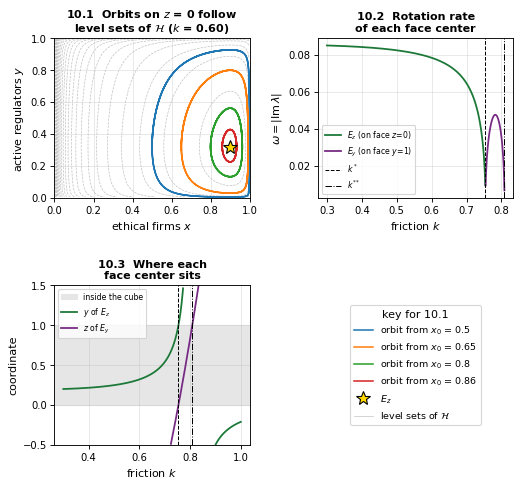

In [13]:
# Figure 10: orbits vs. level sets of H, and the two face centers as k changes
fig10 = plt.figure(figsize=(TEXTW, 6.6))
gs10 = gridspec.GridSpec(2, 2, figure=fig10, wspace=0.35, hspace=0.55)
a = fig10.add_subplot(gs10[0, 0])
xg, yg = np.meshgrid(np.linspace(0.005, 0.995, 300), np.linspace(0.005, 0.995, 300))
a.contour(xg, yg, egt.conserved_H_z0(xg, yg, p, K0), levels=30, colors="0.75", linewidths=0.6)
for x0v, colv in zip([0.5, 0.65, 0.8, 0.86], ["C0", "C1", "C2", "C3"]):   # from a big loop down to a small one near E_z
    s = egt.simulate((x0v, 0.3, 0.0), np.linspace(0, 300, 3000), k=K0)
    a.plot(s[:, 0], s[:, 1], color=colv, lw=1.4, label=f"orbit from $x_0$ = {x0v}")
a.plot(Ez[0], Ez[1], "*", color="gold", ms=13, mec="k", label="$E_z$")
a.plot([], [], color="0.75", lw=0.6, label="level sets of $\\mathcal{H}$")
a.set_xlim(0, 1); a.set_ylim(0, 1); h10, l10 = a.get_legend_handles_labels()
a.set_title("10.1  Orbits on $z$ = 0 follow\nlevel sets of $\\mathcal{H}$ ($k$ = 0.60)"); a.set_xlabel("ethical firms $x$"); a.set_ylabel("active regulators $y$")
ks = np.linspace(0.3, 1.0, 600); omz, omy, yz, zy = [], [], [], []
for kv in ks:
    fps = egt.face_fixed_points(p, kv); ez, ey = fps["z=0"], fps["y=1"]
    omz.append(np.max(np.abs(np.linalg.eigvals(egt.jacobian(ez, p, kv)).imag)) if 0 < ez[1] < 1 else np.nan)
    omy.append(np.max(np.abs(np.linalg.eigvals(egt.jacobian(ey, p, kv)).imag)) if 0 < ey[2] < 1 else np.nan)
    yz.append(ez[1]); zy.append(ey[2])
a = fig10.add_subplot(gs10[0, 1])
a.plot(ks, omz, color="#1b7837", label="$E_z$ (on face $z$=0)"); a.plot(ks, omy, color="#762a83", label="$E_y$ (on face $y$=1)")
for kv, ls, lab in [(KS, "--", "$k^*$"), (KSS, "-.", "$k^{**}$")]:
    a.axvline(kv, color="k", ls=ls, lw=0.9, label=lab)
a.set_title("10.2  Rotation rate of each face center"); a.set_xlabel("friction $k$"); a.set_ylabel("$\\omega = |\\mathrm{Im}\\,\\lambda|$")
a.legend(fontsize=7, loc="lower left")
a = fig10.add_subplot(gs10[1, 0])
yz_, zy_ = np.array(yz, float), np.array(zy, float)
a.axhspan(0, 1, color="0.9", zorder=0, label="inside the cube")
a.plot(ks, np.where((yz_ > -0.5) & (yz_ < 1.5), yz_, np.nan), color="#1b7837", label="$y$ of $E_z$")
a.plot(ks, np.where((zy_ > -0.5) & (zy_ < 1.5), zy_, np.nan), color="#762a83", label="$z$ of $E_y$")
for kv, ls in [(KS, "--"), (KSS, "-.")]:
    a.axvline(kv, color="k", ls=ls, lw=0.9)
a.set_ylim(-0.5, 1.5); a.set_title("10.3  Where each face center sits"); a.set_xlabel("friction $k$"); a.set_ylabel("coordinate")
a.legend(fontsize=7, loc="upper left")
aK = fig10.add_subplot(gs10[1, 1]); aK.axis("off")
aK.legend(h10, l10, loc="center", fontsize=8.5, title="key for 10.1")
save(fig10, "fig_stability.png")
s = egt.simulate((0.65, 0.2, 0.0), np.linspace(0, 1000, 5001), k=K0)
Hs = egt.conserved_H_z0(s[:, 0], s[:, 1], p, K0)
print(f"ln H along a z=0 orbit: relative variation {np.ptp(Hs) / abs(Hs.mean()):.1e} over t = 1000")

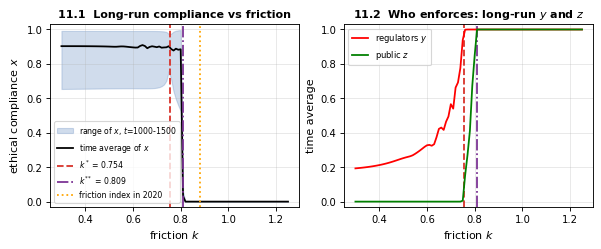

In [14]:
# Figure 11: sweep over k, long runs from the 2010 state
ks11 = np.linspace(0.3, 1.25, 96); lo11, hi11, mx, my, mz = [], [], [], [], []   # steps of 0.01 in k
t11 = np.concatenate([[0.0], np.linspace(1000, 1500, 2501)])   # skip 1000 units of transient, then 3+ cycles
for kv in ks11:
    s = egt.simulate(X0, t11, k=kv)[1:]
    lo11.append(s[:, 0].min()); hi11.append(s[:, 0].max()); mx.append(s[:, 0].mean()); my.append(s[:, 1].mean()); mz.append(s[:, 2].mean())
fig11, (a, b) = plt.subplots(1, 2, figsize=(TEXTW, 3.0), constrained_layout=True)
a.fill_between(ks11, lo11, hi11, color="#4575b4", alpha=0.25, label="range of $x$, $t$=1000-1500")
a.plot(ks11, mx, "k-", label="time average of $x$")
for kv, ls, col, lab in [(KS, "--", "#d73027", f"$k^*$ = {KS:.3f}"), (KSS, "-.", "#7b3294", f"$k^{{**}}$ = {KSS:.3f}")]:
    a.axvline(kv, color=col, ls=ls, label=lab); b.axvline(kv, color=col, ls=ls)
a.axvline(0.88, color="orange", ls=":", label="friction index in 2020")
a.set_xlabel("friction $k$"); a.set_ylabel("ethical compliance $x$"); a.set_ylim(-0.03, 1.03); a.legend(fontsize=7, loc="lower left")
a.set_title("11.1  Long-run compliance vs friction")
b.plot(ks11, my, "r-", label="regulators $y$"); b.plot(ks11, mz, "g-", label="public $z$")
b.set_xlabel("friction $k$"); b.set_ylabel("time average"); b.set_ylim(-0.03, 1.03); b.legend(fontsize=7.5); b.set_title("11.2  Who enforces: long-run $y$ and $z$")
save(fig11, "fig_bifurcation.png")

cycle-to-cycle ratio of z: [0.558 0.413 0.333 0.302 0.292 0.289 0.288 0.288]; period 104.6; predicted 0.288


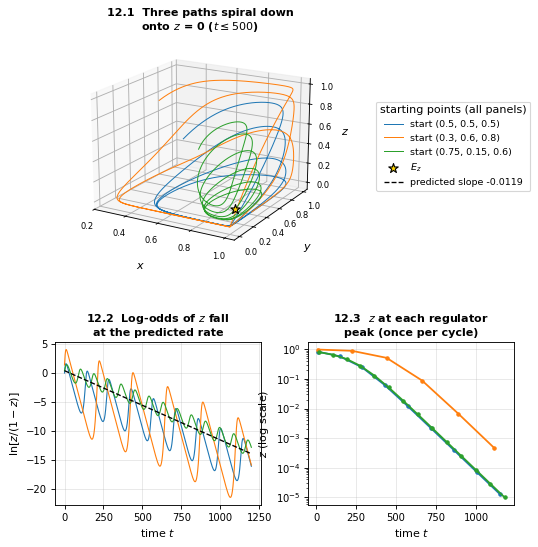

In [15]:
# Figure 12: z dying out, k = 0.60
t12 = np.linspace(0, 1200, 12001)
fig12 = plt.figure(figsize=(TEXTW, 7.6))
gs12 = gridspec.GridSpec(2, 6, figure=fig12, wspace=1.3, hspace=0.45, height_ratios=[1.35, 1])
a3 = fig12.add_subplot(gs12[0, 0:4], projection="3d"); b = fig12.add_subplot(gs12[1, 0:3]); c12 = fig12.add_subplot(gs12[1, 3:6])
for icv, col in zip([(0.5, 0.5, 0.5), (0.3, 0.6, 0.8), (0.75, 0.15, 0.6)], ["C0", "C1", "C2"]):   # three spread-out starts
    s = egt.simulate(icv, t12, k=K0)
    a3.plot(*s[t12 <= 500].T, color=col, lw=0.9, label=f"start {icv}")
    lz = np.log(s[:, 2] / (1 - s[:, 2]))
    b.plot(t12, lz, color=col, lw=1)
    pk, _ = find_peaks(s[:, 1]); c12.semilogy(t12[pk], s[pk, 2], "o-", color=col, ms=3)
slope = p["B_p"] * (XY - XZ)
b.plot(t12, lz[0] + slope * t12, "k--", lw=1.2, label=f"predicted slope {slope:.4f}")
a3.scatter(*Ez, c="gold", s=80, marker="*", edgecolor="k", label="$E_z$")
a3.set_zlabel("$z$", labelpad=-3); a3.set_title("12.1  Three paths spiral down onto $z$ = 0 ($t\\leq500$)"); a3.set_xlabel("$x$"); a3.set_ylabel("$y$"); a3.set_zlabel("$z$")
a3.tick_params(labelsize=7.5, pad=0); a3.view_init(elev=18, azim=-60); a3.set_box_aspect(None, zoom=1.12)
h12, l12 = a3.get_legend_handles_labels(); h12 += b.get_legend_handles_labels()[0]; l12 += b.get_legend_handles_labels()[1]
b.set_title("12.2  Log-odds of $z$ fall\nat the predicted rate"); b.set_xlabel("time $t$"); b.set_ylabel("$\\ln[z/(1-z)]$")
c12.set_title("12.3  $z$ at each regulator\npeak (once per cycle)"); c12.set_xlabel("time $t$"); c12.set_ylabel("$z$ (log scale)")
aK = fig12.add_subplot(gs12[0, 4:6]); aK.axis("off")
aK.legend(h12, l12, loc="center", fontsize=8.5, title="starting points (all panels)")
save(fig12, "fig_zdecay.png")
s = egt.simulate((0.65, 0.2, 0.15), t12, k=K0); pk, _ = find_peaks(s[:, 1])
ratio = s[pk[1:], 2] / s[pk[:-1], 2]
print(f"cycle-to-cycle ratio of z: {np.round(ratio[:8], 3)}; period {np.diff(t12[pk])[-1]:.1f}; predicted {np.exp(slope * np.diff(t12[pk])[-1]):.3f}")

T = 10: [ 0.00442 -0.10161 -0.14269]   T = 6000: [ 0.00071 -0.00168 -0.01255]   predicted third: -0.01191
lambda1 range [-0.0014, 0.0021], lambda3 range [-0.0188, -0.0072]


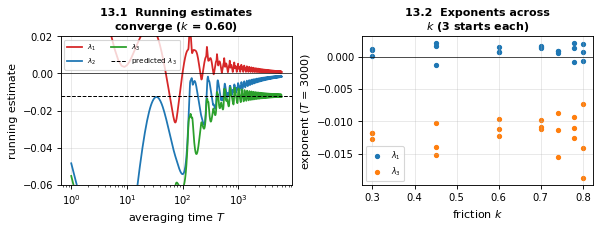

In [16]:
# Figure 13: Lyapunov exponents
le_long, le_hist = egt.lyapunov_spectrum((0.5, 0.5, 0.5), k=K0, T=6000, dt_orth=1.0, p=p, return_history=True)
le_10 = egt.lyapunov_spectrum((0.5, 0.5, 0.5), k=K0, T=10, dt_orth=0.01, p=p)
print(f"T = 10: {np.round(le_10, 5)}   T = 6000: {np.round(le_long, 5)}   predicted third: {slope:.5f}")
rng = np.random.default_rng(1); sweep = []
for kv in [0.3, 0.45, 0.6, 0.7, 0.74, 0.78, 0.8]:     # covers both regimes below k**
    for _ in range(3):
        icv = rng.uniform(0.05, 0.95, 3)
        sweep.append((kv, *egt.lyapunov_spectrum(icv, k=kv, T=3000, dt_orth=1.0, p=p)))   # T=3000 (see 13.1)
sweep = pd.DataFrame(sweep, columns=["k", "lambda1", "lambda2", "lambda3"])
fig13, (a, b) = plt.subplots(1, 2, figsize=(TEXTW, 2.8), constrained_layout=True)
tt = np.arange(1, len(le_hist) + 1)
for j, col in enumerate(["C3", "C0", "C2"]): a.plot(tt, le_hist[:, j], color=col, label=f"$\\lambda_{j+1}$")
a.axhline(slope, color="k", ls="--", lw=0.9, label="predicted $\\lambda_3$"); a.axhline(0, color="k", lw=0.6)
a.set_xscale("log"); a.set_ylim(-0.06, 0.02); a.set_xlabel("averaging time $T$"); a.set_ylabel("running estimate")
a.set_title("13.1  Running estimates converge ($k$ = 0.60)"); a.legend(fontsize=6.5, ncol=2)
b.scatter(sweep["k"], sweep["lambda1"], s=14, label="$\\lambda_1$"); b.scatter(sweep["k"], sweep["lambda3"], s=14, label="$\\lambda_3$")
b.axhline(0, color="k", lw=0.6); b.set_xlabel("friction $k$"); b.set_ylabel("exponent ($T$ = 3000)")
b.set_title("13.2  Exponents across $k$ (3 starts each)"); b.legend(fontsize=7)
save(fig13, "fig_lyapunov.png")
print(f"lambda1 range [{sweep.lambda1.min():.4f}, {sweep.lambda1.max():.4f}], lambda3 range [{sweep.lambda3.min():.4f}, {sweep.lambda3.max():.4f}]")

## 12. Figures 14-18: outside data
These don't depend on the model. Every penalty and revenue number, with its source and
access date, is in `data/firm_classification.csv`.

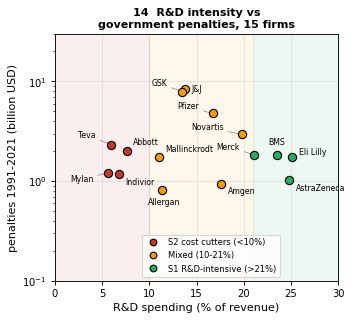

In [17]:
firms = egt.load_firms()
EMP_SIZE = (4.3, 3.9)   # common size for Figs 14-17
color_map = {"S2": "#C0392B", "Mixed": "#F39C12", "S1": "#27AE60"}
FIRM_OFFSETS = {"Teva": (-30, 6), "Abbott": (6, 6), "Mylan": (-34, -8), "Indivior": (6, -10), "Mallinckrodt": (6, 5),
                "J&J": (6, -3), "GSK": (-28, 5), "Pfizer": (-32, 4), "Amgen": (6, -9), "Allergan": (-12, -13), "Novartis": (-46, 4),
                "Merck": (-34, 5), "Eli Lilly": (6, 2), "AstraZeneca": (6, -10), "BMS": (-8, 9)}
fig14, a = plt.subplots(figsize=EMP_SIZE, constrained_layout=True)
a.axvspan(0, 10, color="#C0392B", alpha=0.08); a.axvspan(10, 21, color="#F39C12", alpha=0.08); a.axvspan(21, 32, color="#27AE60", alpha=0.08)
for _, r in firms.iterrows():
    xy = (r.rnd_pct_of_revenue, r.total_penalties_musd / 1000)
    a.scatter(*xy, color=color_map[r.strategy_zone], s=55, edgecolor="k", zorder=5)
    off = FIRM_OFFSETS.get(r.firm, (4, 4))
    a.annotate(r.firm, xy, xytext=off, textcoords="offset points", fontsize=7,
               arrowprops=dict(arrowstyle="-", color="0.5", lw=0.6) if max(map(abs, off)) > 8 else None)
a.legend(handles=[Line2D([], [], marker="o", ls="", mfc=color_map[z], mec="k", label=l) for z, l in
                  [("S2", "S2 cost cutters (<10%)"), ("Mixed", "Mixed (10-21%)"), ("S1", "S1 R&D-intensive (>21%)")]],
         loc="lower center", bbox_to_anchor=(0.55, 0.0), fontsize=7.5)
a.set_xlim(0, 30); a.set_yscale("log"); a.set_ylim(0.1, 30)
a.set_title("14  R&D intensity vs government penalties, 15 firms"); a.set_xlabel("R&D spending (% of revenue)"); a.set_ylabel("penalties 1991-2021 (billion USD)")
save(fig14, "fig_rnd_penalty.png", tight=False)

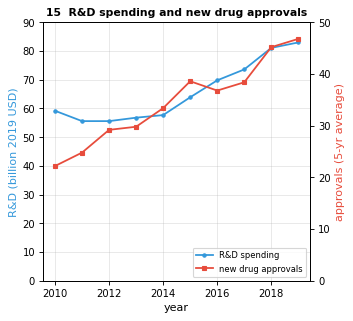

In [18]:
# CBO (2021): R&D in billions of 2019 dollars and the 5-year moving average of approvals
yrs = np.arange(2010, 2020)
rnd = [59.2, 55.6, 55.6, 56.8, 57.7, 63.9, 69.8, 73.6, 81.1, 83.0]
appr = [22.2, 24.8, 29.2, 29.8, 33.4, 38.6, 36.8, 38.4, 45.2, 46.8]
fig15, a = plt.subplots(figsize=EMP_SIZE, constrained_layout=True)
a.plot(yrs, rnd, "o-", color="#3498DB", ms=3, label="R&D spending"); a.set_ylabel("R&D (billion 2019 USD)", color="#3498DB"); a.set_ylim(0, 90)
b = a.twinx(); b.plot(yrs, appr, "s-", color="#E74C3C", ms=3, label="new drug approvals"); b.set_ylabel("approvals (5-yr average)", color="#E74C3C"); b.set_ylim(0, 50); b.grid(False)
a.set_xlabel("year"); a.set_title("15  R&D spending and new drug approvals"); a.legend(handles=a.get_lines() + b.get_lines(), loc="lower right", fontsize=7.5)
save(fig15, "fig_rnd_approvals.png", tight=False)

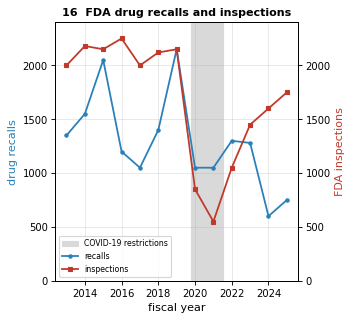

In [19]:
# FDA Data Dashboard counts by fiscal year
yrs16 = np.arange(2013, 2026)
recalls = [1350, 1550, 2050, 1200, 1050, 1400, 2150, 1050, 1050, 1300, 1280, 600, 750]
insp = [2000, 2180, 2150, 2250, 2000, 2120, 2150, 850, 550, 1050, 1450, 1600, 1750]
fig16, a = plt.subplots(figsize=EMP_SIZE, constrained_layout=True)
a.axvspan(2019.8, 2021.5, color="0.85", zorder=0, label="COVID-19 restrictions")
a.plot(yrs16, recalls, "o-", color="#2980B9", ms=3, label="recalls"); a.set_ylabel("drug recalls", color="#2980B9"); a.set_ylim(0, 2400)
b = a.twinx(); b.plot(yrs16, insp, "s-", color="#C0392B", ms=3, label="inspections"); b.set_ylabel("FDA inspections", color="#C0392B"); b.set_ylim(0, 2400); b.grid(False)
a.set_xlabel("fiscal year"); a.set_title("16  FDA drug recalls and inspections")
a.legend(handles=[a.patches[0]] + a.get_lines() + b.get_lines(), loc="lower left", fontsize=7)
save(fig16, "fig_recalls.png", tight=False)

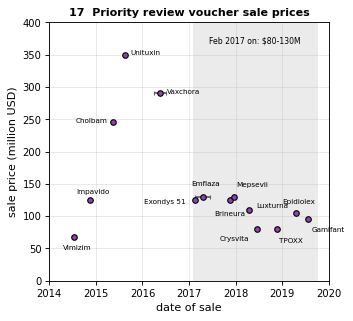

In [20]:
# GAO-20-251, Appendix I Table 3: every voucher sold with a public price through FY2019
prv = pd.DataFrame([
    ("Vimizim", 2014, 7, 67.5), ("Impavido", 2014, 11, 125), ("Cholbam", 2015, 5, 245), ("Unituxin", 2015, 8, 350),
    ("Vaxchora", 2016, 5, 290), ("Exondys 51", 2017, 2, 125), ("Emflaza", 2017, 4, 130), ("Brineura", 2017, 11, 125),
    ("Mepsevii", 2017, 12, 130), ("Luxturna", 2018, 4, 110), ("Crysvita", 2018, 6, 80.6), ("TPOXX", 2018, 11, 80),
    ("Epidiolex", 2019, 4, 105), ("Gamifant", 2019, 7, 95)], columns=["product", "year", "month", "price_musd"])
prv["date"] = prv.year + (prv.month - 0.5) / 12
xerr = np.zeros((2, len(prv)))      # GAO dates two sales only roughly: Vaxchora "Q2 2016", Emflaza "Feb-Jun 2017"
xerr[:, prv.index[prv["product"] == "Vaxchora"][0]] = 1.5 / 12
xerr[:, prv.index[prv["product"] == "Emflaza"][0]] = 2 / 12
PRV_OFF = {"Vimizim": (-10, -11), "Impavido": (-12, 6), "Cholbam": (-34, 0), "Unituxin": (5, 0), "Vaxchora": (6, 0),
           "Exondys 51": (-46, -3), "Emflaza": (-10, 10), "Brineura": (-14, -14), "Mepsevii": (2, 9), "Luxturna": (6, 2),
           "Crysvita": (-34, -11), "TPOXX": (2, -12), "Epidiolex": (-12, 8), "Gamifant": (4, -11)}
fig17, a = plt.subplots(figsize=EMP_SIZE, constrained_layout=True)
a.axvspan(2017 + 1 / 12, 2019.75, color="0.92", zorder=0)
a.errorbar(prv.date, prv.price_musd, xerr=xerr, fmt="o", color="#8E44AD", mec="k", ms=5, ecolor="0.4", capsize=2, zorder=5)
for _, r in prv.iterrows():
    a.annotate(r["product"], (r.date, r.price_musd), xytext=PRV_OFF[r["product"]], textcoords="offset points", fontsize=6.5)
a.text(2018.4, 368, "Feb 2017 on: $80-130M", fontsize=7, ha="center")
a.set_xlim(2014, 2020); a.set_ylim(0, 400); a.set_xlabel("date of sale"); a.set_ylabel("sale price (million USD)"); a.set_title("17  Priority review voucher sale prices")
save(fig17, "fig_prv.png", tight=False)

       n  mean_busd  median_busd
S2     4      1.682        1.610
Mixed  7      3.943        2.948
S1     4      1.610        1.782
            firm strategy_zone  rnd_pct_of_revenue  total_penalties_musd      rev     pct
0       Indivior            S2                 6.8                  1183    785.0  150.70
1           Teva            S2                 6.0                  2326  16887.0   13.77
2          Mylan            S2                 5.6                  1210  11500.5   10.52
3         Abbott            S2                 7.6                  2009  31904.0    6.30
4   Mallinckrodt         Mixed                11.0                  1754   3162.5   55.46
5            GSK         Mixed                13.5                  7921  43920.0   18.04
6            J&J         Mixed                13.8                  8449  82059.0   10.30
7         Pfizer         Mixed                16.7                  4773  51750.0    9.22
8       Novartis         Mixed                19.8        

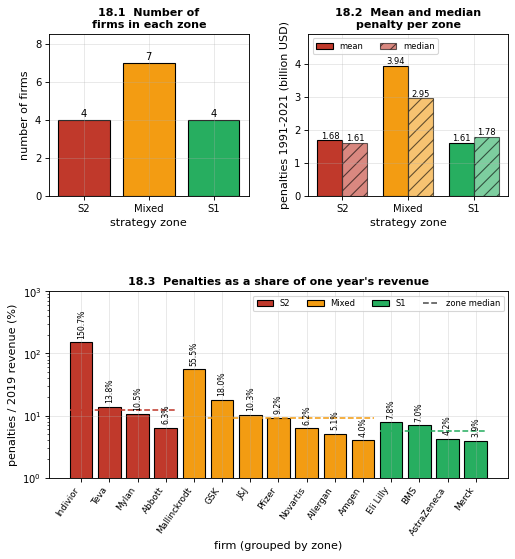

In [21]:
order = ["S2", "Mixed", "S1"]
g = firms.groupby("strategy_zone")["total_penalties_musd"]
counts, means, medians = [g.count()[z] for z in order], [g.mean()[z] / 1000 for z in order], [g.median()[z] / 1000 for z in order]
fig18 = plt.figure(figsize=(TEXTW, 7.2))
gs18 = gridspec.GridSpec(2, 2, figure=fig18, hspace=0.55, wspace=0.3, height_ratios=[1, 1.15])
ax_a, ax_b, ax_c = fig18.add_subplot(gs18[0, 0]), fig18.add_subplot(gs18[0, 1]), fig18.add_subplot(gs18[1, :])
ax_a.bar(order, counts, color=[color_map[z] for z in order], edgecolor="k")
for i_, cnt in enumerate(counts): ax_a.text(i_, cnt + 0.15, str(cnt), ha="center", fontsize=9)
ax_a.set_ylim(0, 8.5); ax_a.set_xlabel("strategy zone"); ax_a.set_ylabel("number of firms"); ax_a.set_title("18.1  Number of firms in each zone")
w = 0.38; xx = np.arange(3)
ax_b.bar(xx - w / 2, means, w, color=[color_map[z] for z in order], edgecolor="k", label="mean")
ax_b.bar(xx + w / 2, medians, w, color=[color_map[z] for z in order], edgecolor="k", hatch="//", alpha=0.6, label="median")
for i_, (m_, d_) in enumerate(zip(means, medians)):
    ax_b.text(i_ - w / 2, m_ + 0.06, f"{m_:.2f}", ha="center", fontsize=7.5); ax_b.text(i_ + w / 2, d_ + 0.06, f"{d_:.2f}", ha="center", fontsize=7.5)
ax_b.set_xticks(xx); ax_b.set_xticklabels(order); ax_b.set_xlabel("strategy zone"); ax_b.set_ylabel("penalties 1991-2021 (billion USD)")
ax_b.set_ylim(0, 4.9); ax_b.set_title("18.2  Mean and median penalty per zone"); ax_b.legend(fontsize=7.5, loc="upper left", ncol=2)
fr = firms.copy(); fr["rev"] = pd.to_numeric(fr["revenue_2019_musd"], errors="coerce")

fr["pct"] = 100 * fr.total_penalties_musd / fr.rev
fr["zone_rank"] = fr.strategy_zone.map({z: i_ for i_, z in enumerate(order)})
fr = fr.sort_values(["zone_rank", "pct"], ascending=[True, False]).reset_index(drop=True)
xs = np.arange(len(fr))
ax_c.bar(xs, fr.pct.fillna(0), color=[color_map[z] for z in fr.strategy_zone], edgecolor="k")
for x_, r_ in zip(xs, fr.itertuples()):
    lab = f"{r_.pct:.1f}%"
    ax_c.text(x_, r_.pct * 1.15, lab, ha="center", va="bottom", fontsize=7, rotation=90)
for z in order:
    med = fr.loc[fr.strategy_zone == z, "pct"].median(); idx = xs[fr.strategy_zone == z]
    ax_c.hlines(med, idx.min() - 0.4, idx.max() + 0.4, color=color_map[z], ls="--", lw=1.4)
ax_c.set_yscale("log"); ax_c.set_ylim(1, 1000)
ax_c.set_xticks(xs); ax_c.set_xticklabels(fr.firm, rotation=55, ha="right", fontsize=8)
ax_c.set_xlabel("firm (grouped by zone)"); ax_c.set_ylabel("penalties / 2019 revenue (%)")
ax_c.set_title("18.3  Penalties as a share of one year's revenue")
ax_c.legend(handles=[Patch(facecolor=color_map[z], edgecolor="k", label=z) for z in order]
            + [Line2D([], [], color="0.3", ls="--", lw=1.4, label="zone median")], fontsize=7.5, loc="upper right", ncol=4)
save(fig18, "fig_zones.png")
print(pd.DataFrame({"n": counts, "mean_busd": np.round(means, 3), "median_busd": np.round(medians, 3)}, index=order))
print(fr[["firm", "strategy_zone", "rnd_pct_of_revenue", "total_penalties_musd", "rev", "pct"]].round(2).to_string())
print("zone medians (%):", fr.groupby("strategy_zone").pct.median().round(2).to_dict())
# leave-one-out check of the zone medians
loo = {z: [] for z in order}
for drop in fr.firm:
    m = fr[fr.firm != drop].groupby("strategy_zone").pct.median()
    for z in order: loo[z].append(m[z])
print("leave-one-out median ranges (%):", {z: (round(min(v), 1), round(max(v), 1)) for z, v in loo.items()})

## 13. Dashboard (Appendix D)
Needs ipywidgets. Without it, the three example settings shown in the paper are drawn instead.

no ipywidgets here, drawing the three examples instead


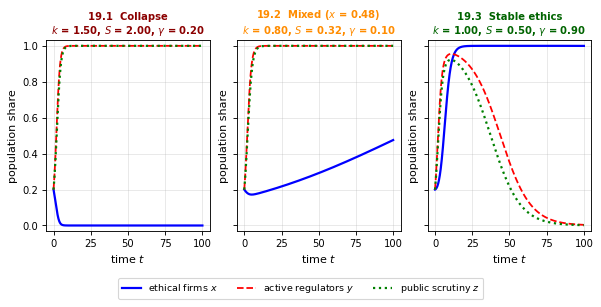

In [22]:
def run_dashboard(k_bureaucracy=KBAR, S_pol=p["S_pol"], gamma=p["gamma"], ax=None, t_end=100, panel=""):
    t = np.linspace(0, t_end, 1000)
    s = egt.simulate((0.2, 0.2, 0.2), t, k=k_bureaucracy, S_pol=S_pol, gamma=gamma)
    own = ax is None
    if own: fig, ax = plt.subplots(figsize=(7, 3))
    ax.plot(t, s[:, 0], "b-", lw=2, label="ethical firms $x$"); ax.plot(t, s[:, 1], "r--", label="regulators $y$"); ax.plot(t, s[:, 2], "g:", lw=2, label="public $z$")
    xe = s[-1, 0]
    # labels used in the paper: at least 0.85 = stable, at most 0.15 = collapse, otherwise mixed
    status, col = (("Stable ethics", "darkgreen") if xe >= 0.85 else ("Collapse", "darkred") if xe <= 0.15 else (f"Mixed ($x$ = {xe:.2f})", "darkorange"))
    ax.set_title(f"{panel}{status}\n$k$ = {k_bureaucracy:.2f}, $S$ = {S_pol:.2f}, $\\gamma$ = {gamma:.2f}", color=col, fontsize=9)
    ax.set_xlabel("time $t$"); ax.set_ylabel("population share"); ax.set_ylim(-0.03, 1.03)
    if own: ax.legend(); plt.show()
    return xe

try:
    from ipywidgets import interact, FloatSlider, Layout
    # slider ranges cover all three outcomes
    interact(lambda k, S, g: run_dashboard(k, S, g),
             k=FloatSlider(value=KBAR, min=0.0, max=1.5, step=0.05, description="friction k", layout=Layout(width="600px")),
             S=FloatSlider(value=p["S_pol"], min=0.0, max=2.0, step=0.05, description="subsidy S", layout=Layout(width="600px")),
             g=FloatSlider(value=p["gamma"], min=0.0, max=2.0, step=0.05, description="public penalty", layout=Layout(width="600px")))
except ImportError:
    print("no ipywidgets here, drawing the three examples instead")

figD, axsD = plt.subplots(1, 3, figsize=(TEXTW, 3.3), sharey=True, constrained_layout=True)
for n_, (a, (kv, sv, gv)) in enumerate(zip(axsD, [(1.50, 2.00, 0.20), (0.80, 0.32, 0.10), (1.00, 0.50, 0.90)])):
    run_dashboard(kv, sv, gv, ax=a, panel=f"19.{n_ + 1}  ")
figD.legend(handles=[Line2D([], [], color="b", lw=2, label="ethical firms $x$"), Line2D([], [], color="r", ls="--", label="active regulators $y$"),
                     Line2D([], [], color="g", ls=":", lw=2, label="public scrutiny $z$")], loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=3, fontsize=8.5)
save(figD, "fig_dashboard.png")